# Projeto M2 - Filtragem, Segmentação e Morfologia

**Disciplina:** Processamento de Imagens - Ciência da Computação / UNIVALI  
**Professor:** Felipe Viel  
**Integrantes:** *Nilson e Andrey*

**Arquivos necessários (na mesma pasta do notebook):** `160068.jpg` (BSD500, conjunto de validação) e a pasta `data/` com `gap-region-filling.tif` e `002f20ad-2ace-499c-9335-c9080bc3e6b5.png`. **Requer Python 3.8 ou superior.** Todos os resultados e números citados na discussão são impressos pelas próprias células.


**O que é manual neste notebook (e por quê).** O professor exige que as operações centrais sejam implementadas pelo grupo. Por isso **não** usamos `np.sort`, `np.sum`, `np.mean`, `np.std`, `np.cumsum`, `np.percentile`, `np.histogram`, `np.bincount`, `np.unique`, `np.random` nem `np.fft`. Foram implementados à mão: gerador de números pseudoaleatórios + ruído Gaussiano (Box-Muller), DFT 2D pela definição, deslocamento do espectro, grade de frequências, preenchimento de bordas (reflexão), PSNR, SSIM, histograma, percentis, Otsu, convolução, Sobel, Watershed, SLIC, morfologia e rotulagem. O NumPy é usado apenas como contêiner de arrays e para operações elemento a elemento (`exp`, `sqrt`, `log`, `cos`, somas e produtos de arrays).

# Parte 1 - Segmentação com Watershed e SLIC

## Objetivo e metodologia

Usamos uma imagem do BSD500, adicionamos ruído Gaussiano, aplicamos filtros passa-baixa no domínio da frequência e comparamos PSNR/SSIM. A frequência de corte é justificada por uma varredura de métricas. O Watershed usa marcadores h-mínimos do gradiente, que evita a grade artificial e reduz bacias rasas. O SLIC desloca os centros iniciais para mínimos locais de gradiente e trabalha com intensidade normalizada. A avaliação compara número de regiões, contornos sobrepostos e a aparência das regiões.

## 1. Bibliotecas, parâmetros e carregamento da imagem

A imagem é carregada diretamente do arquivo `160068.jpg`, que deve estar na **mesma pasta** deste notebook. Não utilizamos Base64 nem incorporamos a imagem ao arquivo `.ipynb`.

A imagem é convertida para tons de cinza e normalizada para o intervalo [0, 1].


Imagem carregada: 160068.jpg
Dimensões: 481 × 321 pixels
Tipo de dado: float64


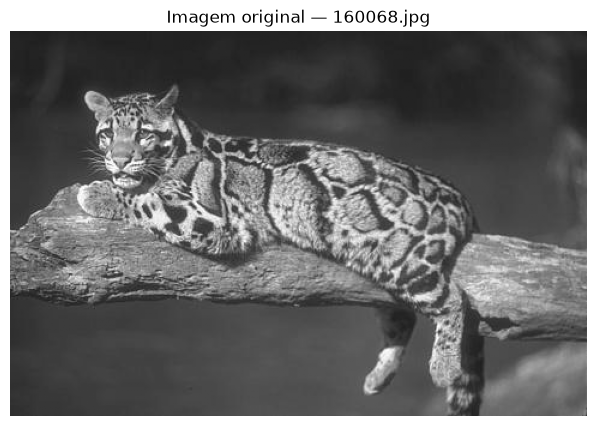

In [1]:
from collections import deque
import heapq
import math
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

SIGMA_RUIDO = 0.06
SEMENTE = 42
D0 = 0.13
ORDEM_BUTTERWORTH = 2
NUM_SUPERPIXELS = 250
COMPACTACIDADE_SLIC = 0.10

CAMINHO_IMAGEM = Path("160068.jpg")

if not CAMINHO_IMAGEM.is_file():
    raise FileNotFoundError(
        "Imagem 160068.jpg não encontrada: coloque-a na mesma pasta do notebook."
    )

# Leitura da imagem em tons de cinza.
imagem_pil = Image.open(CAMINHO_IMAGEM).convert("L")

# Conversão para matriz NumPy e normalização para [0, 1].
original = np.asarray(imagem_pil, dtype=np.float64) / 255.0

altura, largura = original.shape

print(f"Imagem carregada: {CAMINHO_IMAGEM.name}")
print(f"Dimensões: {largura} × {altura} pixels")
print(f"Tipo de dado: {original.dtype}")

plt.figure(figsize=(9, 5))
plt.imshow(original, cmap="gray", vmin=0, vmax=1)
plt.title(f"Imagem original — {CAMINHO_IMAGEM.name}")
plt.axis("off");


### Utilitários manuais

Funções auxiliares implementadas no notebook (somas, histograma, percentil, preenchimento de bordas, gerador pseudoaleatório com ruído Gaussiano por Box-Muller e DFT 2D pela definição). São usadas no restante do trabalho no lugar das funções prontas.

In [2]:
# ===== Utilitários manuais (somas, médias, histograma, percentil, borda) =====
import math

def somar(a):
    # Soma por acumulação explícita.
    total = 0.0
    for v in a.ravel().tolist():
        total += v
    return total

def media(a):
    return somar(a) / a.size

def desvio_padrao(a):
    m = media(a); d = a - m
    return math.sqrt(somar(d * d) / a.size)

def minimo(a):
    menor = None
    for v in a.ravel().tolist():
        if menor is None or v < menor: menor = v
    return menor

def maximo(a):
    maior = None
    for v in a.ravel().tolist():
        if maior is None or v > maior: maior = v
    return maior

def contar_verdadeiros(mascara):
    n = 0
    for v in mascara.ravel().tolist():
        if v: n += 1
    return n

def existe_verdadeiro(mascara):
    # Varre a máscara e para no primeiro True (substitui .any()).
    for v in mascara.ravel().tolist():
        if v: return True
    return False

def todos_finitos(a):
    # Verifica NaN/infinito pixel a pixel (substitui np.isfinite(...).all()).
    for v in a.ravel().tolist():
        if v != v or v in (float("inf"), float("-inf")): return False
    return True

def proporcao(mascara):
    return contar_verdadeiros(mascara) / mascara.size

def contar_valores_distintos(a):
    return len(set(a.ravel().tolist()))

def limitar(a, baixo, alto):
    return np.minimum(np.maximum(a, baixo), alto)

def histograma(indices, n_bins):
    # Conta quantos pixels caem em cada intervalo (indices inteiros em [0, n_bins-1]).
    cont = [0] * n_bins
    for v in indices.ravel().tolist():
        cont[v] += 1
    return cont

def percentil_por_histograma(a, q, n_bins=4096):
    # Percentil q (%) sem ordenar: varre o histograma acumulando as contagens.
    lo, hi = minimo(a), maximo(a)
    if hi <= lo: return lo
    idx = ((a - lo) / (hi - lo) * (n_bins - 1)).astype(np.int64)
    cont = histograma(idx, n_bins); alvo = q / 100.0 * a.size; acumulado = 0
    for b in range(n_bins):
        acumulado += cont[b]
        if acumulado >= alvo:
            return lo + (b / (n_bins - 1)) * (hi - lo)
    return hi

def _indices_borda(n, r, modo):
    i = np.arange(-r, n + r)
    if modo == "edge": return limitar(i, 0, n - 1)
    if n == 1: return i * 0
    periodo = 2 * (n - 1); m = i % periodo          # reflexão periódica (sem repetir a borda)
    return m + (m >= n) * (periodo - 2 * m)

def borda(img, ry, rx, modo="reflect", valor=0):
    # Preenchimento de borda (padding): 'reflect' (espelho), 'edge' (replica) ou 'constante'.
    h, w = img.shape
    if modo == "constante":
        saida = np.full((h + 2*ry, w + 2*rx), valor, dtype=img.dtype); saida[ry:ry+h, rx:rx+w] = img
        return saida
    iy = _indices_borda(h, ry, modo); ix = _indices_borda(w, rx, modo)
    return img[iy[:, None], ix[None, :]]

# ===== Gerador pseudoaleatório próprio (LCG de 64 bits) + Box-Muller =====
def gerar_uniformes(n, semente):
    a, c, M = 6364136223846793005, 1442695040888963407, (1 << 64) - 1
    estado = (semente * 0x9E3779B97F4A7C15 + 1) & M
    for _ in range(8): estado = (a * estado + c) & M   # aquecimento
    saida = [0.0] * n
    for k in range(n):
        estado = (a * estado + c) & M
        saida[k] = ((estado >> 11) + 0.5) / (1 << 53)   # uniforme em (0, 1)
    return np.array(saida)

def ruido_gaussiano(shape, sigma, semente):
    # Box-Muller: z0 = sqrt(-2 ln u1) cos(2 pi u2), z1 = sqrt(-2 ln u1) sin(2 pi u2)
    n = shape[0] * shape[1]; pares = (n + 1) // 2
    u = gerar_uniformes(2 * pares, semente); u1, u2 = u[:pares], u[pares:]
    raio = np.sqrt(-2.0 * np.log(u1)); ang = 2.0 * math.pi * u2
    z = np.concatenate([raio * np.cos(ang), raio * np.sin(ang)])[:n]
    return (sigma * z).reshape(shape)

# ===== DFT 2D pela definição: F = W_M . f . W_N, com W[k,n] = exp(-2*pi*i*k*n/N) =====
_cache_W = {}
def matriz_dft(n):
    if n not in _cache_W:
        k = np.arange(n)
        _cache_W[n] = np.exp(-2j * math.pi * ((k[:, None] * k[None, :]) % n) / n)
    return _cache_W[n]

def dft2(f):
    return matriz_dft(f.shape[0]) @ f @ matriz_dft(f.shape[1])

def idft2(F):
    return (np.conj(matriz_dft(F.shape[0])) @ F @ np.conj(matriz_dft(F.shape[1]))) / F.size

def frequencias(n):
    # Frequências em ciclos/pixel na ordem da DFT: 0, 1/n, ..., -1/n
    k = np.arange(n)
    return (k - n * (k >= (n + 1) // 2)) / n

def deslocar_centro(F):
    return np.roll(np.roll(F, F.shape[0] // 2, axis=0), F.shape[1] // 2, axis=1)

def desfazer_deslocamento(F):
    return np.roll(np.roll(F, -(F.shape[0] // 2), axis=0), -(F.shape[1] // 2), axis=1)


In [3]:
# ===== Validação das funções manuais (propriedades conhecidas) =====
# 1) Ruído Gaussiano: média ~ 0, desvio ~ sigma, regra 68-95
r = ruido_gaussiano((300, 300), 0.06, 123)
m_r, s_r = media(r), desvio_padrao(r)
d1 = proporcao((r > -s_r) & (r < s_r)); d2 = proporcao((r > -2*s_r) & (r < 2*s_r))
assert abs(m_r) < 1e-3 and abs(s_r - 0.06) < 0.0015 and abs(d1 - 0.683) < 0.01 and abs(d2 - 0.954) < 0.01
print(f"Ruído: média={m_r:.5f}, desvio={s_r:.4f} (alvo 0.06), dentro de 1σ={d1:.3f} (0.683), dentro de 2σ={d2:.3f} (0.954)")
# 2) DFT: impulso -> espectro constante; cosseno -> picos em +-k; ida e volta recupera a imagem
imp = np.zeros((16, 12)); imp[0, 0] = 1.0
F_imp = dft2(imp); assert maximo(np.abs(F_imp - 1.0)) < 1e-12
x = np.arange(16)[:, None] * np.ones((1, 12)); cos = np.cos(2 * math.pi * 3 * x / 16)
F_cos = np.abs(dft2(cos)); assert abs(F_cos[3, 0] - 96) < 1e-9 and abs(F_cos[13, 0] - 96) < 1e-9
teste_img = ruido_gaussiano((20, 14), 1.0, 7)
erro_ida_volta = maximo(np.abs(idft2(dft2(teste_img)).real - teste_img)); assert erro_ida_volta < 1e-10
energia_esp = somar(np.abs(dft2(teste_img))**2) / teste_img.size; energia_esp_img = somar(teste_img**2)
assert abs(energia_esp - energia_esp_img) < 1e-8      # Parseval
print(f"DFT: impulso OK, cosseno OK (pico = M·N/2 = 96), erro ida-e-volta={erro_ida_volta:.1e}, Parseval OK")
# 3) frequências e deslocamento
assert list(frequencias(4)) == [0.0, 0.25, -0.5, -0.25] and list(np.round(frequencias(5), 2)) == [0, 0.2, 0.4, -0.4, -0.2]
# 4) borda refletida e histograma/percentil
assert list(borda(np.array([[1, 2, 3, 4]]), 0, 2, "reflect")[0]) == [3, 2, 1, 2, 3, 4, 3, 2]
assert sum(histograma(np.array([0, 1, 1, 3]), 4)) == 4 and histograma(np.array([0, 1, 1, 3]), 4) == [1, 2, 0, 1]
assert abs(percentil_por_histograma(np.arange(1001, dtype=float), 50) - 500) < 1
print("Frequências, borda refletida, histograma e percentil: OK")

Ruído: média=-0.00008, desvio=0.0603 (alvo 0.06), dentro de 1σ=0.684 (0.683), dentro de 2σ=0.954 (0.954)
DFT: impulso OK, cosseno OK (pico = M·N/2 = 96), erro ida-e-volta=8.9e-16, Parseval OK
Frequências, borda refletida, histograma e percentil: OK


### 1.1. Histograma da imagem original

O histograma apresenta a distribuição das intensidades dos pixels da imagem original em tons de cinza. Utilizamos 256 intervalos, correspondentes aos níveis de intensidade de 0 a 255 (representados aqui no intervalo normalizado [0, 1]).

Essa visualização permite observar se há predominância de regiões escuras, intermediárias ou claras e fornece uma indicação do contraste global da imagem.


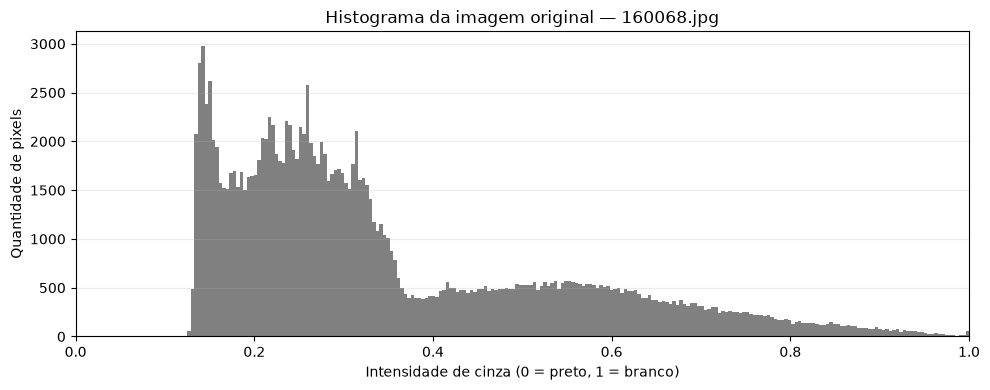

Intensidade mínima: 0.098
Intensidade máxima: 1.000
Intensidade média:  0.348
Desvio-padrão:      0.188


In [4]:
# Histograma da imagem original (contagem manual em 256 intervalos)
indices = limitar((original * 256).astype(np.int64), 0, 255)
contagens = histograma(indices, 256)
centros_bins = (np.arange(256) + 0.5) / 256

plt.figure(figsize=(10, 4))
plt.bar(centros_bins, contagens, width=1/256, color="gray", edgecolor="none")
plt.title("Histograma da imagem original — 160068.jpg")
plt.xlabel("Intensidade de cinza (0 = preto, 1 = branco)")
plt.ylabel("Quantidade de pixels")
plt.xlim(0, 1)
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

print(f"Intensidade mínima: {minimo(original):.3f}")
print(f"Intensidade máxima: {maximo(original):.3f}")
print(f"Intensidade média:  {media(original):.3f}")
print(f"Desvio-padrão:      {desvio_padrao(original):.3f}")

### 1.2. Justificativa da imagem

A imagem apresenta um animal sobre um galho, com texturas na pelagem, regiões de contraste, contornos e detalhes finos. Essas características permitem observar:

- se o ruído cria variações locais que prejudicam a segmentação;
- se a filtragem reduz o ruído sem apagar detalhes importantes;
- se o Watershed produz excesso de regiões em áreas texturizadas;
- como o SLIC agrupa pixels em superpixels compactos.

A imagem não contém uma máscara de referência de segmentação neste experimento. Por isso, a comparação de contornos será feita entre as saídas dos três cenários (original, ruidoso e filtrado), usando F1 de bordas com tolerância espacial de 1,5 pixel. Essa medida avalia a consistência dos contornos em relação ao cenário original; não equivale a acurácia contra uma anotação manual.


## 2. Adição de ruído Gaussiano

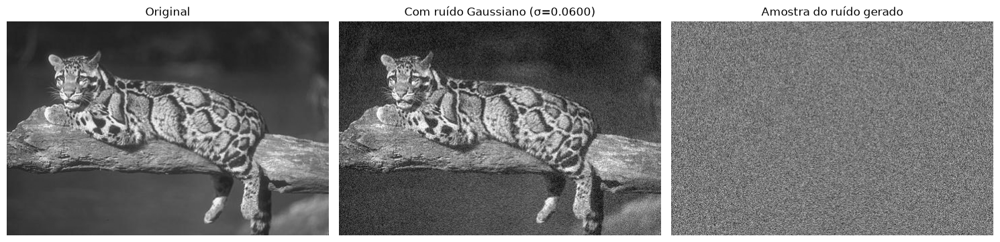

In [5]:
def adicionar_ruido_gaussiano(imagem, sigma, semente=42):
    """Adiciona ruído Gaussiano aditivo (g = f + n, n ~ N(0, sigma²)) e limita o resultado a [0, 1]."""
    ruido = ruido_gaussiano(imagem.shape, sigma, semente)   # gerador próprio (LCG + Box-Muller)
    imagem_ruidosa = limitar(imagem + ruido, 0.0, 1.0)
    return imagem_ruidosa, ruido

ruidosa, matriz_ruido = adicionar_ruido_gaussiano(original, SIGMA_RUIDO, SEMENTE)

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].imshow(original, cmap="gray", vmin=0, vmax=1)
ax[0].set_title("Original")
ax[1].imshow(ruidosa, cmap="gray", vmin=0, vmax=1)
ax[1].set_title(f"Com ruído Gaussiano (σ={SIGMA_RUIDO:.4f})")
ax[2].imshow(matriz_ruido, cmap="gray")
ax[2].set_title("Amostra do ruído gerado")
for a in ax.ravel(): a.axis("off")
plt.tight_layout()

**Interpretação esperada:** o ruído introduz pequenas oscilações de intensidade por toda a imagem. Como ele possui componentes em várias frequências, seu efeito pode ser observado no espectro de Fourier, especialmente nas frequências mais altas.

## 3. Transformada de Fourier e filtragem no domínio da frequência

A Transformada Discreta de Fourier 2D representa a imagem por componentes de frequência. O módulo do espectro será exibido com escala logarítmica para tornar visíveis tanto as baixas quanto as altas magnitudes.

Para reduzir efeitos de borda da periodicidade implícita na DFT, a imagem será refletida antes da FFT e recortada após a transformada inversa.

**DFT implementada pela definição.** A DFT 2D é separável: `F = W_M · f · W_N`, onde `W[k, n] = exp(-2πi·k·n/N)`. Construímos essas matrizes com a fórmula e multiplicamos (sem `np.fft`). A inversa usa o conjugado e divide por `M·N`. A validação (impulso, cosseno, ida-e-volta e Parseval) está na seção de utilitários. O custo é maior que o da FFT (O(N³) em vez de O(N² log N)), aceitável para imagens deste tamanho.

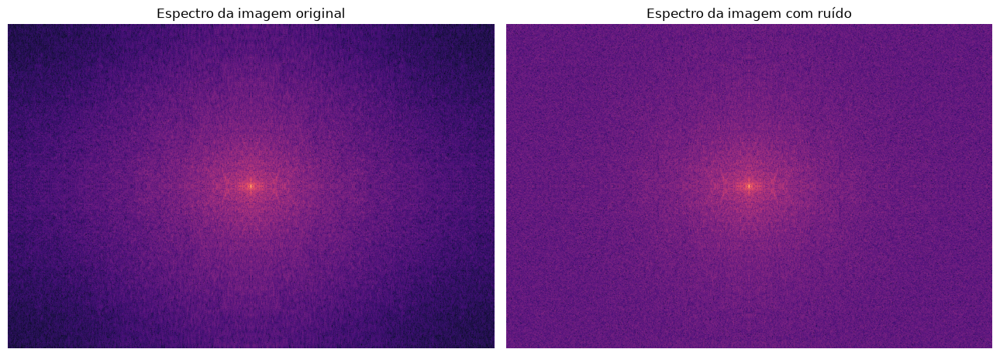

In [6]:
def refletir_imagem(imagem):
    """Adiciona uma borda por reflexão, com largura igual à metade da imagem."""
    py = imagem.shape[0] // 2
    px = imagem.shape[1] // 2
    return borda(imagem, py, px, "reflect"), py, px

def espectro_log(fft_centrada):
    """Retorna o módulo do espectro em escala logarítmica para visualização."""
    return np.log(1.0 + np.sqrt(fft_centrada.real**2 + fft_centrada.imag**2))

def grade_frequencias(shape):
    """Cria a distância radial em ciclos/pixel, com zero no centro do espectro."""
    h, w = shape
    fy = np.roll(frequencias(h), h // 2)
    fx = np.roll(frequencias(w), w // 2)
    FX, FY = np.meshgrid(fx, fy)
    return np.sqrt(FX**2 + FY**2)

def criar_mascara_filtro(shape, tipo, d0=0.12, ordem=2):
    """Constrói máscaras passa-baixa Ideal, Gaussiana ou Butterworth."""
    D = grade_frequencias(shape)
    if tipo == "ideal":
        H = (D <= d0).astype(np.float64)
    elif tipo == "gaussiano":
        H = np.exp(-(D**2) / (2 * d0**2))
    elif tipo == "butterworth":
        H = 1.0 / (1.0 + (D / d0)**(2 * ordem))
    else:
        raise ValueError("Tipo deve ser: ideal, gaussiano ou butterworth.")
    return H

def filtrar_no_dominio_frequencia(imagem, tipo, d0=0.12, ordem=2):
    """Filtra uma imagem: DFT 2D própria, máscara radial H(u,v) e DFT inversa própria."""
    ampliada, py, px = refletir_imagem(imagem)
    F = deslocar_centro(dft2(ampliada))
    H = criar_mascara_filtro(ampliada.shape, tipo, d0, ordem)
    G = F * H
    reconstruida = idft2(desfazer_deslocamento(G)).real
    reconstruida = reconstruida[py:py+imagem.shape[0], px:px+imagem.shape[1]]
    return limitar(reconstruida, 0.0, 1.0), F, G, H

# Espectros da imagem limpa e da imagem ruidosa.
img_pad_original, py, px = refletir_imagem(original)
img_pad_ruidosa, _, _ = refletir_imagem(ruidosa)
F_original = deslocar_centro(dft2(img_pad_original))
F_ruidosa = deslocar_centro(dft2(img_pad_ruidosa))

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
ax[0].imshow(espectro_log(F_original), cmap="magma")
ax[0].set_title("Espectro da imagem original")
ax[1].imshow(espectro_log(F_ruidosa), cmap="magma")
ax[1].set_title("Espectro da imagem com ruído")
for a in ax.ravel(): a.axis("off")
plt.tight_layout()

### 3.1. Filtros avaliados

Serão comparados três filtros passa-baixa:

1. **Ideal:** mantém integralmente as frequências abaixo do corte e elimina as demais. A transição abrupta pode provocar oscilações (ringing).
2. **Gaussiano:** atenua as frequências de maneira suave, sem uma fronteira abrupta.
3. **Butterworth:** controla a suavidade da transição por meio da ordem do filtro.

A frequência de corte `D0` é expressa em ciclos por pixel. Os mesmos parâmetros serão aplicados à imagem ruidosa para permitir uma comparação justa.

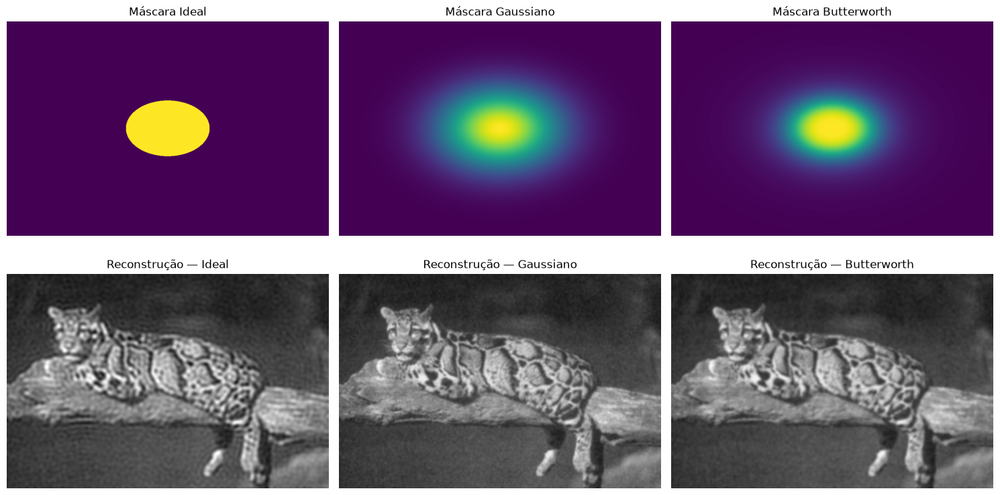

In [7]:
TIPOS_FILTRO = ["ideal", "gaussiano", "butterworth"]
resultados_filtros = {}

for tipo in TIPOS_FILTRO:
    filtrada, F, G, H = filtrar_no_dominio_frequencia(
        ruidosa, tipo, d0=D0, ordem=ORDEM_BUTTERWORTH
    )
    resultados_filtros[tipo] = {
        "imagem": filtrada, "F": F, "G": G, "H": H
    }

fig, ax = plt.subplots(2, 3, figsize=(15, 8))
for j, tipo in enumerate(TIPOS_FILTRO):
    item = resultados_filtros[tipo]
    ax[0, j].imshow(item["H"], cmap="viridis")
    ax[0, j].set_title(f"Máscara {tipo.capitalize()}")
    ax[1, j].imshow(item["imagem"], cmap="gray", vmin=0, vmax=1)
    ax[1, j].set_title(f"Reconstrução — {tipo.capitalize()}")
    ax[0, j].axis("off")
    ax[1, j].axis("off")
plt.tight_layout()

### 3.2. Espectro antes e depois da filtragem

O espectro filtrado é obtido multiplicando o espectro da imagem ruidosa pela máscara passa-baixa. A transformada inversa retorna a imagem ao domínio espacial.

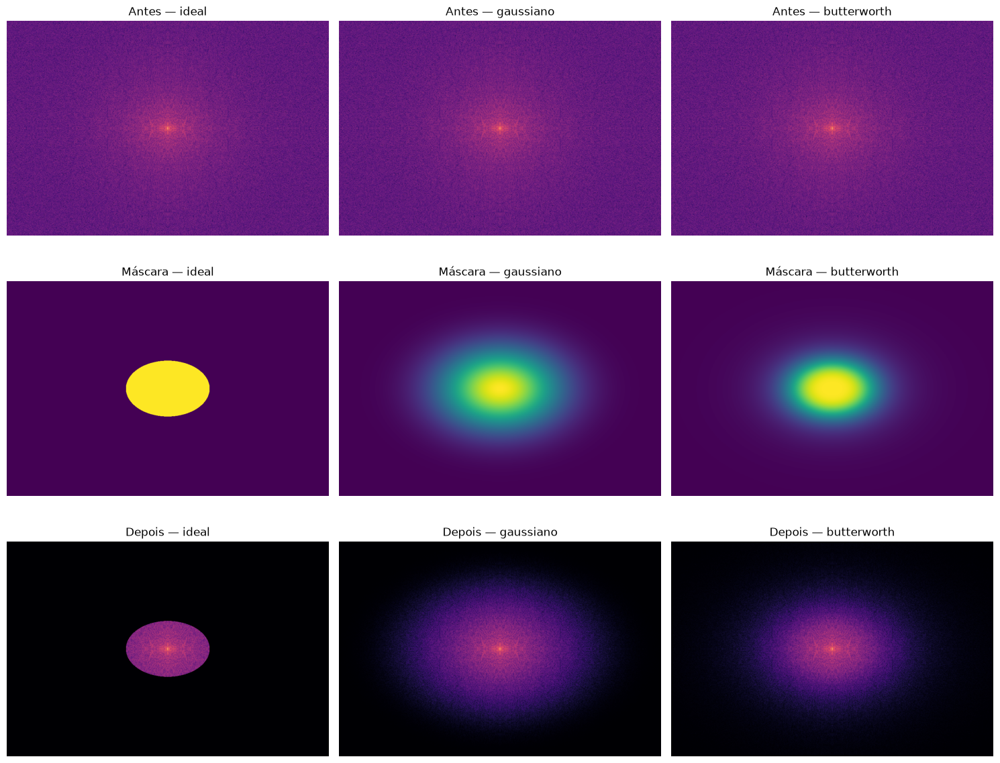

In [8]:
fig, ax = plt.subplots(3, 3, figsize=(15, 12))
for j, tipo in enumerate(TIPOS_FILTRO):
    item = resultados_filtros[tipo]
    ax[0, j].imshow(espectro_log(item["F"]), cmap="magma")
    ax[0, j].set_title(f"Antes — {tipo}")
    ax[1, j].imshow(item["H"], cmap="viridis")
    ax[1, j].set_title(f"Máscara — {tipo}")
    ax[2, j].imshow(espectro_log(item["G"]), cmap="magma")
    ax[2, j].set_title(f"Depois — {tipo}")
    for i in range(3): ax[i, j].axis("off")
plt.tight_layout()

### 3.3. Comparação espacial: original, ruidosa e filtradas

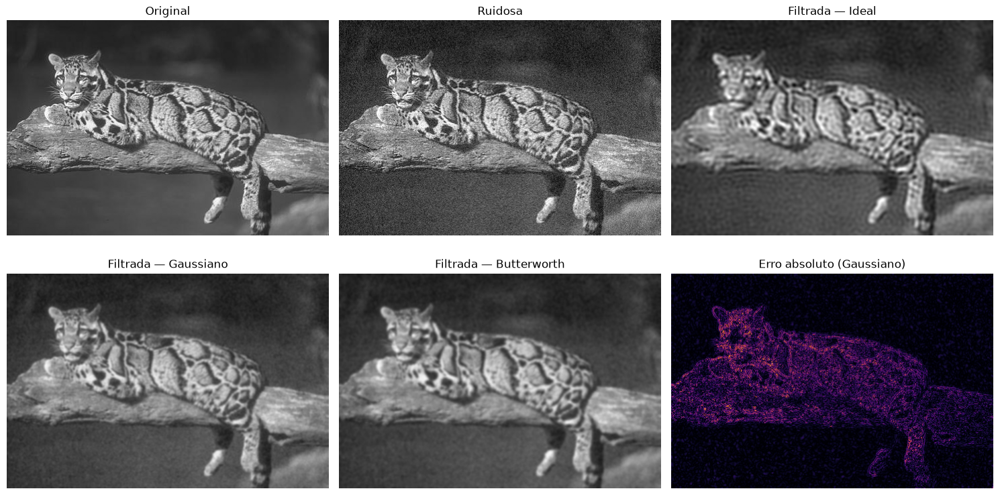

In [9]:
fig, ax = plt.subplots(2, 3, figsize=(15, 8))
ax[0, 0].imshow(original, cmap="gray", vmin=0, vmax=1)
ax[0, 0].set_title("Original")
ax[0, 1].imshow(ruidosa, cmap="gray", vmin=0, vmax=1)
ax[0, 1].set_title("Ruidosa")
ax[0, 2].imshow(resultados_filtros["ideal"]["imagem"], cmap="gray", vmin=0, vmax=1)
ax[0, 2].set_title("Filtrada — Ideal")
ax[1, 0].imshow(resultados_filtros["gaussiano"]["imagem"], cmap="gray", vmin=0, vmax=1)
ax[1, 0].set_title("Filtrada — Gaussiano")
ax[1, 1].imshow(resultados_filtros["butterworth"]["imagem"], cmap="gray", vmin=0, vmax=1)
ax[1, 1].set_title("Filtrada — Butterworth")
erro = np.abs(original - resultados_filtros["gaussiano"]["imagem"])
ax[1, 2].imshow(erro, cmap="inferno")
ax[1, 2].set_title("Erro absoluto (Gaussiano)")
for a in ax.ravel(): a.axis("off")
plt.tight_layout()

## 4. Avaliação da filtragem: PSNR e SSIM

O PSNR quantifica o erro quadrático médio em relação à imagem original.

Como as imagens estão normalizadas, `MAX = 1`.

O SSIM é implementado com estatísticas locais calculadas por uma janela uniforme. Ele compara luminância, contraste e estrutura. É uma implementação didática do índice estrutural, não uma reprodução bit a bit de todas as variantes de bibliotecas especializadas.

In [10]:
def calcular_psnr(referencia, imagem, data_range=1.0):
    """Calcula PSNR manualmente: 10*log10(MAX² / MSE)."""
    d = referencia.astype(np.float64) - imagem.astype(np.float64)
    mse = somar(d * d) / d.size
    if mse == 0:
        return float("inf")
    return 10.0 * math.log10((data_range**2) / mse)

def filtro_media_borda(imagem, tamanho=7):
    """Média local em janela tamanho x tamanho (soma das cópias deslocadas), borda refletida."""
    r = tamanho // 2
    p = borda(imagem, r, r, "reflect")
    h, w = imagem.shape
    soma = np.zeros((h, w), dtype=np.float64)
    for dy in range(tamanho):
        for dx in range(tamanho):
            soma += p[dy:dy + h, dx:dx + w]
    return soma / (tamanho * tamanho)

def calcular_ssim(referencia, imagem, data_range=1.0, tamanho=7):
    """Calcula SSIM médio com médias e variâncias locais por janela uniforme."""
    x = referencia.astype(np.float64)
    y = imagem.astype(np.float64)
    mu_x = filtro_media_borda(x, tamanho)
    mu_y = filtro_media_borda(y, tamanho)
    mu_x2, mu_y2, mu_xy = mu_x**2, mu_y**2, mu_x*mu_y
    sigma_x2 = filtro_media_borda(x*x, tamanho) - mu_x2
    sigma_y2 = filtro_media_borda(y*y, tamanho) - mu_y2
    sigma_xy = filtro_media_borda(x*y, tamanho) - mu_xy
    c1 = (0.01 * data_range)**2
    c2 = (0.03 * data_range)**2
    mapa = ((2*mu_xy + c1) * (2*sigma_xy + c2)) / (
        (mu_x2 + mu_y2 + c1) * (sigma_x2 + sigma_y2 + c2) + 1e-12
    )
    return media(mapa)

linhas_metricas = []
linhas_metricas.append(("Imagem ruidosa", calcular_psnr(original, ruidosa),
                        calcular_ssim(original, ruidosa)))
for tipo in TIPOS_FILTRO:
    img = resultados_filtros[tipo]["imagem"]
    linhas_metricas.append((tipo.capitalize(), calcular_psnr(original, img),
                            calcular_ssim(original, img)))

print(f"{'Condição':<22} {'PSNR (dB)':>12} {'SSIM':>12}")
print("-" * 48)
for nome, p, s in linhas_metricas:
    print(f"{nome:<22} {p:>12.3f} {s:>12.4f}")

Condição                  PSNR (dB)         SSIM
------------------------------------------------
Imagem ruidosa               24.444       0.4859
Ideal                        24.612       0.7370
Gaussiano                    26.472       0.8104
Butterworth                  25.721       0.8044


## 5. Escolha do filtro: histogramas e varredura

Os histogramas mostram como o ruído altera as intensidades e como a filtragem reduz sua dispersão. Os gráficos de PSNR e SSIM testam diversos cortes; por isso, o corte usado não é arbitrário. A faixa vai de 0,04 a 0,40 ciclos/pixel para que o pico de cada métrica apareça dentro do intervalo testado.

In [11]:
filtrada_gaussiana = resultados_filtros["gaussiano"]["imagem"]

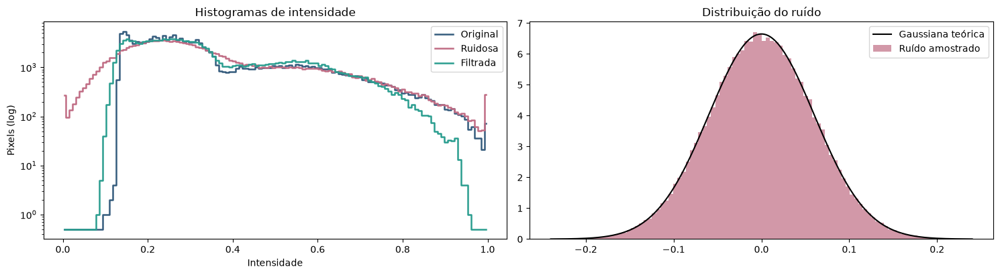

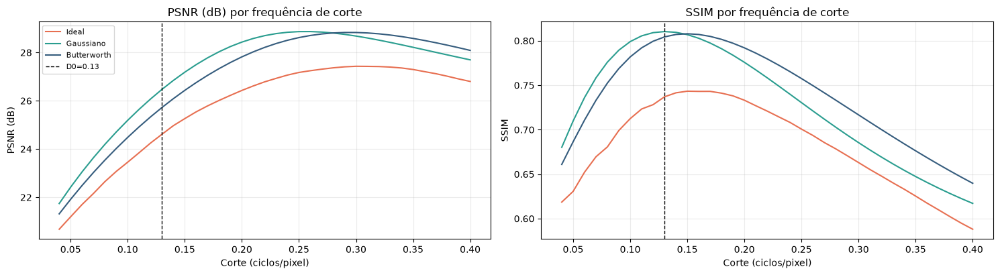

Filtro        D0 pico PSNR     PSNR  D0 pico SSIM     SSIM
ideal                 0.30    27.43          0.15   0.7433
gaussiano             0.26    28.87          0.13   0.8104
butterworth           0.29    28.83          0.15   0.8079


In [12]:
# Histogramas comparáveis e varredura que justifica o corte escolhido.
fig, ax = plt.subplots(1, 2, figsize=(15, 4.2))
centros128 = (np.arange(128) + 0.5) / 128
for img, nome, cor in [(original,"Original","#355C7D"),(ruidosa,"Ruidosa","#C06C84"),(filtrada_gaussiana,"Filtrada","#2A9D8F")]:
    cont = histograma(limitar((img * 128).astype(np.int64), 0, 127), 128)   # histograma manual
    ax[0].step(centros128, [max(c, 0.5) for c in cont], where="mid", lw=1.8, color=cor, label=nome)
ax[0].set_yscale("log"); ax[0].set_title("Histogramas de intensidade"); ax[0].set_xlabel("Intensidade"); ax[0].set_ylabel("Pixels (log)"); ax[0].legend()
x=np.linspace(-4*SIGMA_RUIDO,4*SIGMA_RUIDO,300)
# Densidade empírica do ruído: histograma manual com 100 intervalos em [-4σ, 4σ], normalizado pela área.
lim = 4*SIGMA_RUIDO; larg_bin = 2*lim/100
idx_r = limitar(((matriz_ruido + lim) / larg_bin).astype(np.int64), 0, 99)
dens = np.array(histograma(idx_r, 100)) / (matriz_ruido.size * larg_bin)
ax[1].bar(-lim + (np.arange(100) + 0.5) * larg_bin, dens, width=larg_bin, color="#C06C84", alpha=.7, label="Ruído amostrado")
ax[1].plot(x,np.exp(-x*x/(2*SIGMA_RUIDO**2))/(SIGMA_RUIDO*np.sqrt(2*np.pi)),color="black",label="Gaussiana teórica")
ax[1].set_title("Distribuição do ruído"); ax[1].legend(); fig.tight_layout(); plt.show()

# Faixa ampla de cortes: mostra o pico do SSIM e o pico do PSNR.
cortes=np.round(np.arange(.04,.401,.01),2); curvas={t:[] for t in TIPOS_FILTRO}
for t in TIPOS_FILTRO:
    for d in cortes:
        teste,*_=filtrar_no_dominio_frequencia(ruidosa,t,d0=float(d),ordem=ORDEM_BUTTERWORTH)
        curvas[t].append((calcular_psnr(original,teste),calcular_ssim(original,teste)))
fig,ax=plt.subplots(1,2,figsize=(15,4.2))
for t,cor in zip(TIPOS_FILTRO,["#E76F51","#2A9D8F","#355C7D"]):
    ax[0].plot(cortes,[v[0] for v in curvas[t]],label=t.capitalize(),color=cor)
    ax[1].plot(cortes,[v[1] for v in curvas[t]],label=t.capitalize(),color=cor)
for a,nome in zip(ax,["PSNR (dB)","SSIM"]):
    a.axvline(D0,color="black",ls="--",lw=1,label=f"D0={D0:.2f}"); a.set_xlabel("Corte (ciclos/pixel)"); a.set_ylabel(nome); a.set_title(nome+" por frequência de corte"); a.grid(alpha=.25)
ax[0].legend(fontsize=8); fig.tight_layout(); plt.show()

# Picos de cada métrica por filtro (busca manual do máximo).
print(f"{'Filtro':<12} {'D0 pico PSNR':>13} {'PSNR':>8} {'D0 pico SSIM':>13} {'SSIM':>8}")
for t in TIPOS_FILTRO:
    ip = iS = 0
    for k in range(len(cortes)):
        if curvas[t][k][0] > curvas[t][ip][0]: ip = k
        if curvas[t][k][1] > curvas[t][iS][1]: iS = k
    print(f"{t:<12} {cortes[ip]:>13.2f} {curvas[t][ip][0]:>8.2f} {cortes[iS]:>13.2f} {curvas[t][iS][1]:>8.4f}")


### 5.1. Ordem do Butterworth (1, 2 e 4)

Como na prática de filtragem em frequência do professor, comparamos ordens do Butterworth com o mesmo `D0`. Ordens maiores aproximam o filtro ideal (transição mais abrupta e mais *ringing*).

Butterworth         PSNR (dB)         SSIM
------------------------------------------
ordem 1                26.246       0.8090
ordem 2                25.721       0.8044
ordem 4                25.228       0.7860


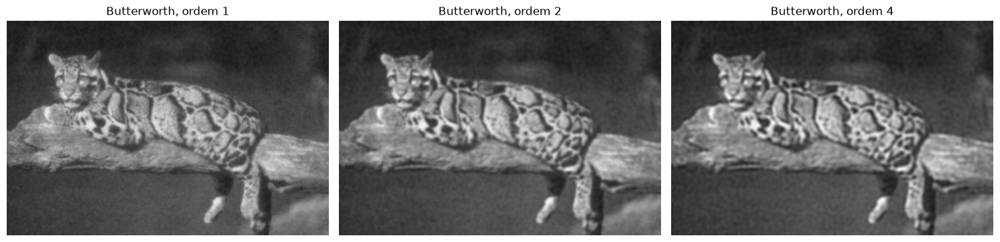

In [13]:
print(f"{'Butterworth':<16} {'PSNR (dB)':>12} {'SSIM':>12}")
print("-" * 42)
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
for j, n in enumerate((1, 2, 4)):
    img_n = filtrar_no_dominio_frequencia(ruidosa, "butterworth", d0=D0, ordem=n)[0]
    print(f"{'ordem ' + str(n):<16} {calcular_psnr(original, img_n):>12.3f} {calcular_ssim(original, img_n):>12.4f}")
    ax[j].imshow(img_n, cmap="gray", vmin=0, vmax=1); ax[j].set_title(f"Butterworth, ordem {n}"); ax[j].axis("off")
plt.tight_layout(); plt.show()

## 6. Segmentação própria: Watershed e SLIC


O gradiente de Sobel é calculado por convolução implementada no notebook. Para o Watershed, a reconstrução por erosão remove mínimos rasos antes da inundação. Para o SLIC, cada centro é reposicionado fora de bordas fortes e a compactação está na mesma escala das intensidades [0, 1].

In [14]:
def convolucao_2d(imagem, kernel):
    """Convolução 2D manual por deslocamentos do kernel, com borda refletida."""
    kh, kw = kernel.shape
    py, px = kh // 2, kw // 2
    p = borda(imagem, py, px, "reflect")
    saida = np.zeros_like(imagem, dtype=np.float64)
    k = kernel[::-1, ::-1]
    h, w = imagem.shape
    for ky in range(kh):
        for kx in range(kw):
            saida += k[ky, kx] * p[ky:ky + h, kx:kx + w]
    return saida

SOBEL_X = np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], dtype=float) / 8
SOBEL_Y = SOBEL_X.T

def calcular_gradiente(imagem):
    gx = convolucao_2d(imagem, SOBEL_X)
    gy = convolucao_2d(imagem, SOBEL_Y)
    magnitude = np.sqrt(gx**2 + gy**2)
    return magnitude / (maximo(magnitude) + 1e-12)

def mapa_contornos(rotulos):
    """Marca pixels que possuem ao menos um vizinho com rótulo diferente."""
    borda = np.zeros(rotulos.shape, dtype=bool)
    for dy, dx in [(-1,0), (1,0), (0,-1), (0,1)]:
        deslocado = np.roll(rotulos, (dy, dx), axis=(0,1))
        borda |= (rotulos != deslocado)
    borda[[0, -1], :] = False
    borda[:, [0, -1]] = False
    return borda


In [15]:
def watershed_proprio(superficie, marcadores):
    """Inundação prioritária multi-fonte; retorna rótulos das bacias."""
    h, w = superficie.shape
    rotulos = np.zeros((h, w), dtype=np.int32)
    visitado = np.zeros((h, w), dtype=bool)
    fila = []
    mascara_marcadores = marcadores > 0
    ys, xs = np.nonzero(marcadores)
    for y, x in zip(ys, xs):
        lab = int(marcadores[y, x])
        heapq.heappush(fila, (float(superficie[y, x]), int(y), int(x), lab))
    vizinhos = [(-1,-1), (-1,0), (-1,1), (0,-1),
                (0,1), (1,-1), (1,0), (1,1)]
    while fila:
        custo, y, x, lab = heapq.heappop(fila)
        if visitado[y, x]:
            continue
        visitado[y, x] = True
        rotulos[y, x] = lab
        for dy, dx in vizinhos:
            ny, nx = y+dy, x+dx
            if (0 <= ny < h and 0 <= nx < w and not visitado[ny, nx]
                    and not mascara_marcadores[ny, nx]):
                novo_custo = max(custo, float(superficie[ny, nx]))
                heapq.heappush(fila, (novo_custo, ny, nx, lab))
    # Marca linhas divisórias entre bacias com rótulo -1, como na prática.
    fronteira = np.zeros((h, w), dtype=bool)
    for dy, dx in vizinhos:
        deslocado = np.roll(rotulos, (dy, dx), axis=(0, 1))
        fronteira |= (rotulos > 0) & (deslocado > 0) & (rotulos != deslocado)
    fronteira[[0, -1], :] = False
    fronteira[:, [0, -1]] = False
    fronteira &= ~mascara_marcadores
    rotulos[fronteira] = -1
    return rotulos


In [16]:
filtrada_gaussiana = resultados_filtros["gaussiano"]["imagem"]
ENTRADAS = {"Original": original, "Ruidosa": ruidosa, "Filtrada (Gaussiano)": filtrada_gaussiana}

In [17]:
# Watershed por marcadores e SLIC, conforme a prática de segmentação da disciplina.
# Marcadores h-mínimos substituem a grade regular no Watershed.
def _erosao3(img):
    h, w = img.shape
    p = borda(img, 1, 1, "edge")
    out = img.copy()
    for dy in range(3):
        for dx in range(3):
            np.minimum(out, p[dy:dy+h, dx:dx+w], out=out)
    return out

def _reconstrucao_erosao(marcador, mascara):
    atual = marcador.copy()
    while True:
        prox = np.maximum(_erosao3(atual), mascara)
        if not existe_verdadeiro(prox != atual):
            return atual
        atual = prox

def _rotular_binario(mascara):
    h, w = mascara.shape
    rot = np.zeros((h, w), dtype=np.int32)
    n = 0
    viz = [(-1,-1), (-1,0), (-1,1), (0,-1), (0,1), (1,-1), (1,0), (1,1)]
    for y, x in zip(*np.nonzero(mascara)):
        if rot[y, x]:
            continue
        n += 1; rot[y, x] = n; fila = [(int(y), int(x))]
        while fila:
            cy, cx = fila.pop()
            for dy, dx in viz:
                ny, nx = cy+dy, cx+dx
                if 0 <= ny < h and 0 <= nx < w and mascara[ny, nx] and not rot[ny, nx]:
                    rot[ny, nx] = n; fila.append((ny, nx))
    return rot

def _marcadores_hmin(grad, h=0.20):
    aterrado = _reconstrucao_erosao(grad + h, grad)
    minimos = _reconstrucao_erosao(aterrado + 1e-6, aterrado) > aterrado
    marc = _rotular_binario(minimos)
    if maximo(marc) == 0:
        menor, y, x = 1e18, 0, 0
        for yy_ in range(grad.shape[0]):
            for xx_ in range(grad.shape[1]):
                if grad[yy_, xx_] < menor: menor, y, x = grad[yy_, xx_], yy_, xx_
        marc[y, x] = 1
    return marc

def executar_watershed(imagem, _ignorado=None, h_minimo=0.20):
    grad = calcular_gradiente(imagem)
    marc = _marcadores_hmin(grad, h_minimo)
    return watershed_proprio(grad, marc), grad, marc

# SLIC: centros deslocados para mínimos de gradiente e compactação compatível com intensidade normalizada.
def _atualizar_centros(rotulos, lista_y, lista_x, lista_i, cy, cx, ci):
    # Novo centro = média de posição e intensidade dos pixels de cada rótulo (acumulação explícita).
    K = len(cy); n = [0] * K; sy = [0.0] * K; sx = [0.0] * K; si = [0.0] * K
    for lab, y, x, v in zip(rotulos, lista_y, lista_x, lista_i):
        n[lab] += 1; sy[lab] += y; sx[lab] += x; si[lab] += v
    for k in range(K):
        if n[k] > 0:
            cy[k], cx[k], ci[k] = sy[k] / n[k], sx[k] / n[k], si[k] / n[k]

def executar_slic_proprio(imagem, numero_superpixels=250, compactacidade=0.10, iteracoes=10):
    img = imagem.astype(float); h, w = img.shape
    passo = max(4, int(round(np.sqrt(h*w/numero_superpixels))))
    ys, xs = np.meshgrid(np.arange(passo//2, h, passo), np.arange(passo//2, w, passo), indexing="ij")
    cy, cx = ys.ravel().astype(float), xs.ravel().astype(float)
    grad = calcular_gradiente(img)
    for k in range(len(cy)):
        y, x = int(cy[k]), int(cx[k]); y0, y1 = max(0,y-1), min(h,y+2); x0, x1 = max(0,x-1), min(w,x+2)
        melhor_g, by, bx = 1e18, y, x
        for py_ in range(y0, y1):
            for px_ in range(x0, x1):
                if grad[py_, px_] < melhor_g: melhor_g, by, bx = grad[py_, px_], py_, px_
        cy[k], cx[k] = by, bx
    ci = img[cy.astype(int), cx.astype(int)]; yy, xx = np.indices((h,w)); peso = (compactacidade/passo)**2
    lista_y, lista_x, lista_i = yy.ravel().tolist(), xx.ravel().tolist(), img.ravel().tolist()
    for _ in range(iteracoes):
        melhor = np.full((h,w), np.inf); labels = np.full((h,w), -1, dtype=np.int32)
        for k, (y,x,intensidade) in enumerate(zip(cy,cx,ci)):
            y0,y1=max(0,int(y-passo)),min(h,int(y+passo+1)); x0,x1=max(0,int(x-passo)),min(w,int(x+passo+1))
            d=(img[y0:y1,x0:x1]-intensidade)**2+peso*((yy[y0:y1,x0:x1]-y)**2+(xx[y0:y1,x0:x1]-x)**2)
            m=d<melhor[y0:y1,x0:x1]; melhor[y0:y1,x0:x1][m]=d[m]; labels[y0:y1,x0:x1][m]=k
        _atualizar_centros(labels.ravel().tolist(), lista_y, lista_x, lista_i, cy, cx, ci)
    return labels+1, passo

# Conectividade: conta componentes conexos (vizinhança-4) por rótulo e funde os muito pequenos ao vizinho.
def impor_conectividade(labels, passo, fracao=0.25):
    h, w = labels.shape; novo = -np.ones((h, w), dtype=np.int32); minimo = int(fracao*passo*passo); n = 0
    for y in range(h):
        for x in range(w):
            if novo[y, x] >= 0: continue
            vizinho = -1
            for ny, nx in ((y, x-1), (y-1, x), (y, x+1), (y+1, x)):
                if 0 <= ny < h and 0 <= nx < w and novo[ny, nx] >= 0: vizinho = novo[ny, nx]; break
            lab = labels[y, x]; novo[y, x] = n; pilha = [(y, x)]; comp = [(y, x)]
            while pilha:
                cy, cx = pilha.pop()
                for ny, nx in ((cy-1, cx), (cy+1, cx), (cy, cx-1), (cy, cx+1)):
                    if 0 <= ny < h and 0 <= nx < w and novo[ny, nx] < 0 and labels[ny, nx] == lab:
                        novo[ny, nx] = n; pilha.append((ny, nx)); comp.append((ny, nx))
            if len(comp) < minimo and vizinho >= 0:
                for cy, cx in comp: novo[cy, cx] = vizinho
            else:
                n += 1
    mapa = {}; saida = []
    for v in novo.ravel().tolist():
        if v not in mapa: mapa[v] = len(mapa) + 1
        saida.append(mapa[v])
    return np.array(saida, dtype=np.int32).reshape(novo.shape)

# Executa as segmentações nas três entradas com os mesmos parâmetros.
resultados_segmentacao = {}
for nome, img in ENTRADAS.items():
    w_labels, grad, marc = executar_watershed(img, h_minimo=0.20)
    s_bruto, passo_slic = executar_slic_proprio(img, NUM_SUPERPIXELS, COMPACTACIDADE_SLIC)
    resultados_segmentacao[nome] = {"watershed": w_labels, "gradiente": grad, "marcadores": marc,
                                    "slic_bruto": s_bruto, "slic": impor_conectividade(s_bruto, passo_slic)}
print("Segmentações: Watershed (h-mínimos) e SLIC (bruto + versão com conectividade imposta).")


Segmentações: Watershed (h-mínimos) e SLIC (bruto + versão com conectividade imposta).


In [18]:
def imagem_media_por_regiao(imagem, rotulos):
    """Substitui cada região por sua intensidade média (acumulação manual por rótulo)."""
    soma = {}; qtd = {}
    for lab, v in zip(rotulos.ravel().tolist(), imagem.ravel().tolist()):
        soma[lab] = soma.get(lab, 0.0) + v; qtd[lab] = qtd.get(lab, 0) + 1
    media_rot = {lab: soma[lab] / qtd[lab] for lab in soma}
    return np.array([media_rot[lab] for lab in rotulos.ravel().tolist()]).reshape(rotulos.shape)

## 7. Comparação dos resultados

Para cada condição, apresentamos o número de regiões, os contornos sobrepostos e a imagem média por superpixel. A contagem do SLIC considera componentes conexos reais, e não apenas a quantidade de sementes/centros. Também comparamos os contornos das imagens ruidosa e filtrada com os contornos da imagem original por meio do F1 de bordas, com tolerância de 1,5 pixel. Como não há máscara manual de referência, essa medida expressa estabilidade em relação ao cenário original, não qualidade semântica absoluta.


In [19]:
def contar_regioes(rotulos):
    return len([r for r in set(rotulos.ravel().tolist()) if r > 0])

def contar_componentes_slic(rotulos):
    """Conta componentes 8-conexos de cada rótulo, não apenas centros do SLIC."""
    h, w = rotulos.shape
    visitado = np.zeros((h, w), dtype=bool)
    total = 0
    vizinhos = [(-1,-1), (-1,0), (-1,1), (0,-1), (0,1), (1,-1), (1,0), (1,1)]
    for y in range(h):
        for x in range(w):
            if visitado[y, x] or rotulos[y, x] <= 0:
                continue
            total += 1
            rotulo = rotulos[y, x]
            visitado[y, x] = True
            fila = deque([(y, x)])
            while fila:
                cy, cx = fila.popleft()
                for dy, dx in vizinhos:
                    ny, nx = cy + dy, cx + dx
                    if (0 <= ny < h and 0 <= nx < w and not visitado[ny, nx]
                            and rotulos[ny, nx] == rotulo):
                        visitado[ny, nx] = True
                        fila.append((ny, nx))
    return total

print(f"{'Entrada':<22} {'Watershed':>10} {'SLIC rótulos':>13} {'SLIC comp.conexos':>18} {'SLIC c/ conectiv.':>18}")
print("-" * 84)
for nome, res in resultados_segmentacao.items():
    nw = contar_regioes(res["watershed"]); nr = contar_regioes(res["slic_bruto"])
    nc = contar_componentes_slic(res["slic_bruto"]); nf = contar_regioes(res["slic"])
    res["contagens"] = (nw, nr, nc, nf)
    print(f"{nome:<22} {nw:>10d} {nr:>13d} {nc:>18d} {nf:>18d}")


Entrada                 Watershed  SLIC rótulos  SLIC comp.conexos  SLIC c/ conectiv.
------------------------------------------------------------------------------------
Original                      149           247               3569                230
Ruidosa                       118           247              10671                210
Filtrada (Gaussiano)          121           247                817                248


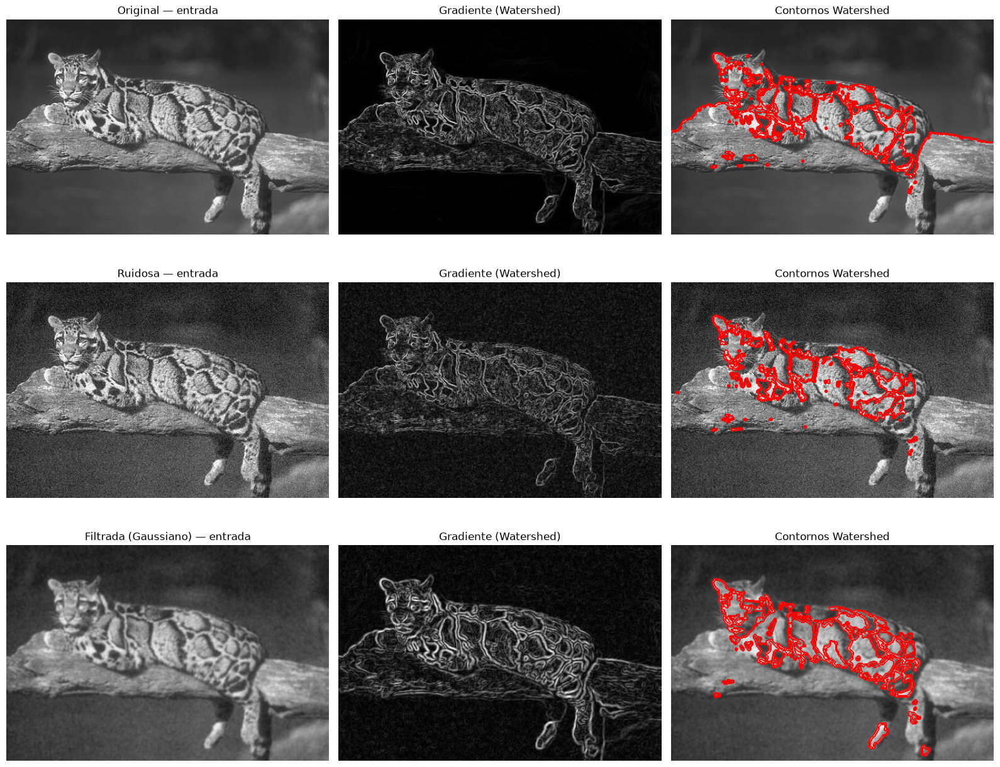

In [20]:
fig, ax = plt.subplots(3, 3, figsize=(16, 13))
for i, (nome, img) in enumerate(ENTRADAS.items()):
    res = resultados_segmentacao[nome]
    ax[i, 0].imshow(img, cmap="gray", vmin=0, vmax=1)
    ax[i, 0].set_title(f"{nome} — entrada")
    ax[i, 1].imshow(res["gradiente"], cmap="gray")
    ax[i, 1].set_title("Gradiente (Watershed)")
    # Exibe as fronteiras do Watershed sobre a imagem de entrada.
    rgb = np.repeat(img[..., None], 3, axis=2)
    rgb[mapa_contornos(res["watershed"])] = [1, 0, 0]
    ax[i, 2].imshow(rgb)
    ax[i, 2].set_title("Contornos Watershed")
    for j in range(3): ax[i, j].axis("off")
plt.tight_layout()

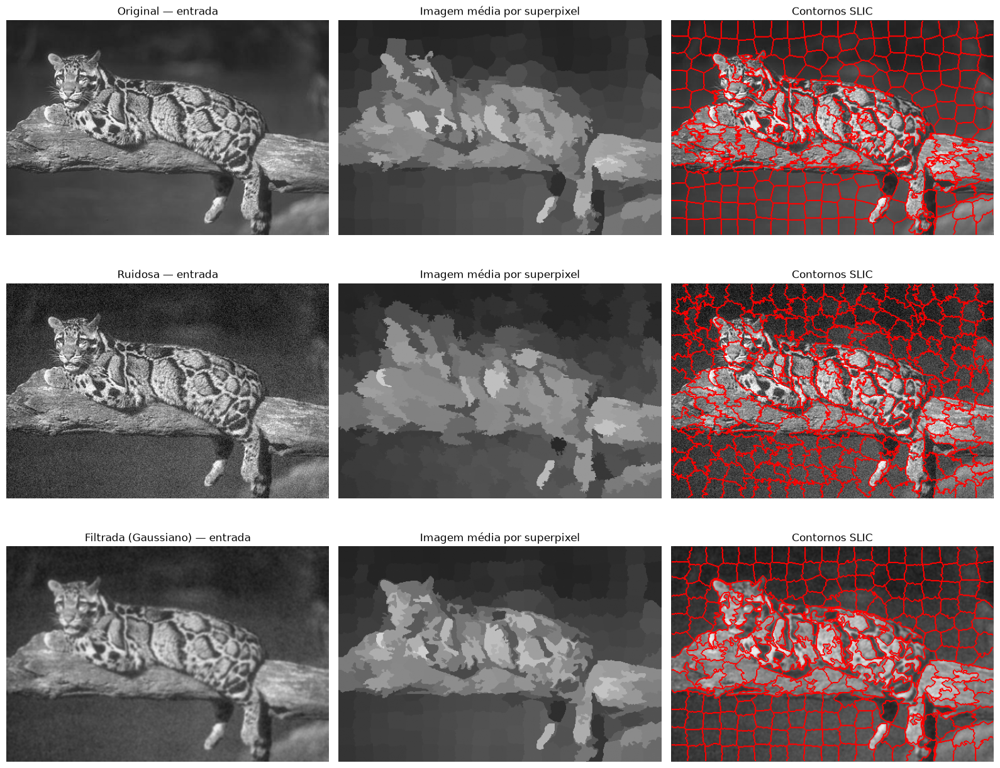

In [21]:
fig, ax = plt.subplots(3, 3, figsize=(16, 13))
for i, (nome, img) in enumerate(ENTRADAS.items()):
    labels = resultados_segmentacao[nome]["slic"]
    media = imagem_media_por_regiao(img, labels)
    ax[i, 0].imshow(img, cmap="gray", vmin=0, vmax=1)
    ax[i, 0].set_title(f"{nome} — entrada")
    ax[i, 1].imshow(media, cmap="gray", vmin=0, vmax=1)
    ax[i, 1].set_title("Imagem média por superpixel")
    rgb = np.repeat(img[..., None], 3, axis=2)
    rgb[mapa_contornos(labels)] = [1, 0, 0]
    ax[i, 2].imshow(rgb)
    ax[i, 2].set_title("Contornos SLIC")
    for j in range(3): ax[i, j].axis("off")
plt.tight_layout()

### 7.1. Tabela-resumo das regiões


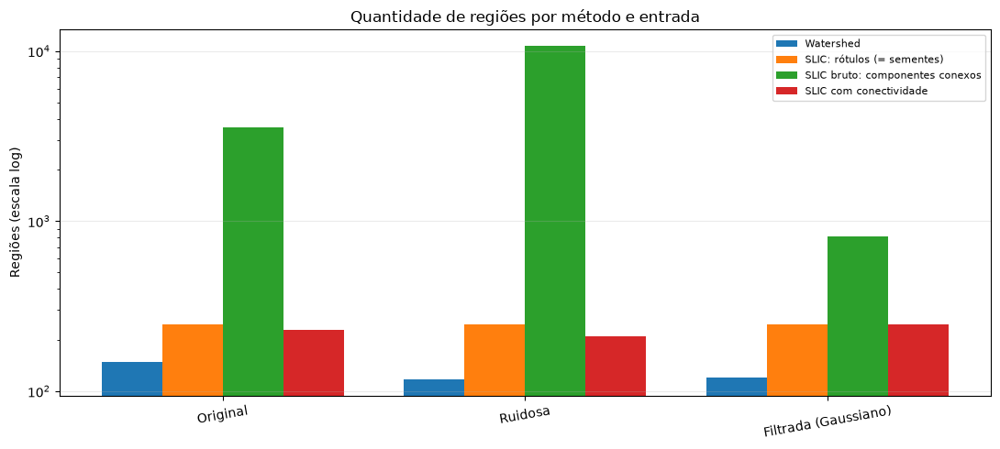

In [22]:
nomes_entradas = list(ENTRADAS.keys())
fig, ax = plt.subplots(figsize=(11, 5))
x = np.arange(len(nomes_entradas)); lb = 0.2
for k, (rot, idx) in enumerate([("Watershed", 0), ("SLIC: rótulos (= sementes)", 1), ("SLIC bruto: componentes conexos", 2), ("SLIC com conectividade", 3)]):
    ax.bar(x + (k-1.5)*lb, [resultados_segmentacao[n]["contagens"][idx] for n in nomes_entradas], lb, label=rot)
ax.set_xticks(x, nomes_entradas, rotation=10); ax.set_yscale("log"); ax.set_ylabel("Regiões (escala log)")
ax.set_title("Quantidade de regiões por método e entrada"); ax.legend(fontsize=8); ax.grid(axis="y", alpha=0.25)
plt.tight_layout(); plt.show()

### 7.2. Comparação quantitativa dos contornos (F1 de bordas)

Os contornos da imagem ruidosa e da imagem filtrada são comparados aos contornos da segmentação da imagem original, separadamente para Watershed e SLIC. Um pixel de borda é considerado correspondente quando existe uma borda de referência a até 1,5 pixel de distância. Precisão e revocação são combinadas pela média harmônica (F1). A tolerância é implementada por deslocamentos locais, sem usar uma função pronta de comparação de bordas.

Esta comparação mede estabilidade em relação à segmentação da imagem original. Como não há ground truth manual, não deve ser interpretada como medida de acurácia semântica.


In [23]:
def dilatar_bordas_tolerancia(bordas, tolerancia=1.5):
    """Expande bordas por vizinhança euclidiana até a tolerância indicada."""
    raio = int(np.ceil(tolerancia))
    h, w = bordas.shape
    padded = borda(bordas, raio, raio, "constante", False)
    expandida = np.zeros_like(bordas, dtype=bool)
    for dy in range(-raio, raio + 1):
        for dx in range(-raio, raio + 1):
            if dy*dy + dx*dx <= tolerancia*tolerancia:
                expandida |= padded[raio+dy:raio+dy+h, raio+dx:raio+dx+w]
    return expandida

def f1_bordas(referencia, candidata, tolerancia=1.5):
    """F1 simétrico de bordas com tolerância espacial em pixels."""
    ref = np.asarray(referencia, dtype=bool)
    cand = np.asarray(candidata, dtype=bool)
    if ref.shape != cand.shape:
        raise ValueError("As duas imagens de bordas devem ter o mesmo formato.")
    n_ref, n_cand = contar_verdadeiros(ref), contar_verdadeiros(cand)
    if n_ref == 0 and n_cand == 0:
        return 1.0, 1.0, 1.0
    if n_ref == 0 or n_cand == 0:
        return 0.0, 0.0, 0.0
    ref_expandida = dilatar_bordas_tolerancia(ref, tolerancia)
    cand_expandida = dilatar_bordas_tolerancia(cand, tolerancia)
    precisao = contar_verdadeiros(cand & ref_expandida) / n_cand
    revocacao = contar_verdadeiros(ref & cand_expandida) / n_ref
    f1 = 0.0 if precisao + revocacao == 0 else 2*precisao*revocacao/(precisao+revocacao)
    return precisao, revocacao, f1

linhas_f1 = []
for metodo in ("watershed", "slic_bruto", "slic"):
    borda_original = mapa_contornos(resultados_segmentacao["Original"][metodo])
    for nome in ("Ruidosa", "Filtrada (Gaussiano)"):
        borda_candidata = mapa_contornos(resultados_segmentacao[nome][metodo])
        p, r, f1 = f1_bordas(borda_original, borda_candidata, tolerancia=1.5)
        linhas_f1.append(({"watershed": "Watershed", "slic_bruto": "SLIC bruto", "slic": "SLIC conexo"}[metodo], nome, p, r, f1))

print(f'{"Método":<12} {"Comparação":<24} {"Precisão":>10} {"Revocação":>10} {"F1":>10}')
print("-" * 72)
for metodo, nome, p, r, f1 in linhas_f1:
    print(f"{metodo:<12} {nome:<24} {p:>10.4f} {r:>10.4f} {f1:>10.4f}")


Método       Comparação                 Precisão  Revocação         F1
------------------------------------------------------------------------
Watershed    Ruidosa                      0.8846     0.7135     0.7899
Watershed    Filtrada (Gaussiano)         0.7279     0.8002     0.7623
SLIC bruto   Ruidosa                      0.5667     0.9945     0.7220
SLIC bruto   Filtrada (Gaussiano)         0.8877     0.7758     0.8280
SLIC conexo  Ruidosa                      0.5367     0.6032     0.5680
SLIC conexo  Filtrada (Gaussiano)         0.7019     0.7468     0.7237


### 7.3. Sensibilidade do Watershed ao parâmetro h

O parâmetro `h` decide quais mínimos viram marcadores: com `h` pequeno, mínimos rasos (inclusive os criados por ruído) geram regiões; com `h` grande, o método ignora o ruído, mas também detalhes. Variamos `h` nas três entradas.

Entrada                     h=0.02    h=0.05     h=0.1     h=0.2
----------------------------------------------------------------
Original                      4019      2357      1004       149
Ruidosa                      10528      4058      1092       118
Filtrada (Gaussiano)          4825      1561       623       121


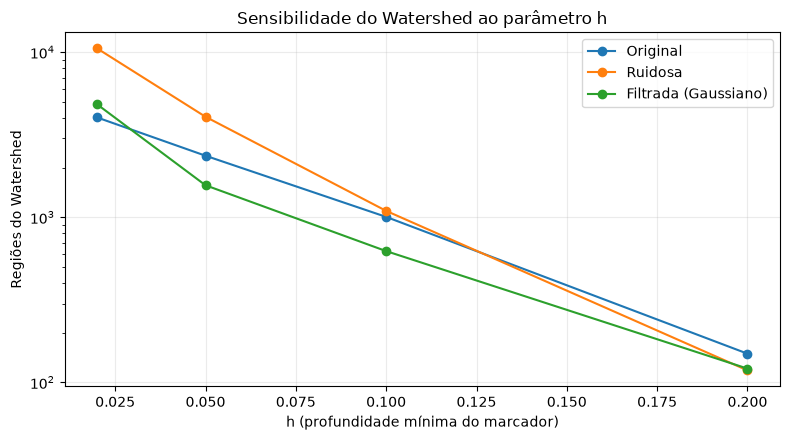

In [24]:
H_LISTA = [0.02, 0.05, 0.10, 0.20]
sens = {nome: [contar_regioes(executar_watershed(img, h_minimo=hh)[0]) for hh in H_LISTA] for nome, img in ENTRADAS.items()}
print(f"{'Entrada':<24}" + "".join(f"{'h=' + str(hh):>10}" for hh in H_LISTA))
print("-" * (24 + 10*len(H_LISTA)))
for nome, valores in sens.items():
    print(f"{nome:<24}" + "".join(f"{v:>10d}" for v in valores))
plt.figure(figsize=(8, 4.5))
for nome, valores in sens.items(): plt.plot(H_LISTA, valores, "-o", label=nome)
plt.xlabel("h (profundidade mínima do marcador)"); plt.ylabel("Regiões do Watershed"); plt.yscale("log")
plt.title("Sensibilidade do Watershed ao parâmetro h"); plt.grid(alpha=0.25); plt.legend(); plt.tight_layout(); plt.show()

## 8. Discussão dos resultados

Os números abaixo são impressos pela execução corrente (nada é copiado de execuções antigas). A célula de resumo lista os valores brutos e a célula seguinte os interpreta.

**Metodologia de análise.** As três entradas (original, ruidosa e filtrada) usam exatamente os mesmos parâmetros. A comparação combina: (i) PSNR/SSIM para a filtragem; (ii) número de regiões; (iii) contornos sobrepostos à imagem de entrada; (iv) F1 de bordas em relação à segmentação da imagem original (tolerância de 1,5 px) e (v) sensibilidade do Watershed a `h`. Como não há máscara de referência, o F1 mede **estabilidade** dos contornos, não acurácia semântica.

In [25]:
# Resumo quantitativo gerado a partir da execução corrente.
metricas = {nome.lower(): {"PSNR": psnr, "SSIM": ssim} for nome, psnr, ssim in linhas_metricas[1:]}
melhor_ssim, v_ssim = max(metricas.items(), key=lambda it: it[1]["SSIM"])
melhor_psnr, v_psnr = max(metricas.items(), key=lambda it: it[1]["PSNR"])
print(f"Ruído Gaussiano: sigma={SIGMA_RUIDO:.3f}, semente={SEMENTE}, D0={D0}.")
print(f"Maior PSNR: {melhor_psnr.capitalize()} ({v_psnr['PSNR']:.2f} dB) | Maior SSIM: {melhor_ssim.capitalize()} ({v_ssim['SSIM']:.4f}).")
for nome, res in resultados_segmentacao.items():
    nw, nr, nc, nf = res["contagens"]
    print(f"{nome}: Watershed={nw} | SLIC rótulos={nr}, comp. conexos={nc} (fragmentos extras: {nc-nr}), após conectividade={nf}.")
for metodo, nome, p, r, f1 in linhas_f1:
    print(f"F1 de bordas vs original - {metodo} / {nome}: precisão={p:.3f}, revocação={r:.3f}, F1={f1:.3f}.")

Ruído Gaussiano: sigma=0.060, semente=42, D0=0.13.
Maior PSNR: Gaussiano (26.47 dB) | Maior SSIM: Gaussiano (0.8104).
Original: Watershed=149 | SLIC rótulos=247, comp. conexos=3569 (fragmentos extras: 3322), após conectividade=230.
Ruidosa: Watershed=118 | SLIC rótulos=247, comp. conexos=10671 (fragmentos extras: 10424), após conectividade=210.
Filtrada (Gaussiano): Watershed=121 | SLIC rótulos=247, comp. conexos=817 (fragmentos extras: 570), após conectividade=248.
F1 de bordas vs original - Watershed / Ruidosa: precisão=0.885, revocação=0.713, F1=0.790.
F1 de bordas vs original - Watershed / Filtrada (Gaussiano): precisão=0.728, revocação=0.800, F1=0.762.
F1 de bordas vs original - SLIC bruto / Ruidosa: precisão=0.567, revocação=0.994, F1=0.722.
F1 de bordas vs original - SLIC bruto / Filtrada (Gaussiano): precisão=0.888, revocação=0.776, F1=0.828.
F1 de bordas vs original - SLIC conexo / Ruidosa: precisão=0.537, revocação=0.603, F1=0.568.
F1 de bordas vs original - SLIC conexo / Fil

In [26]:
# Interpretação gerada a partir dos valores calculados acima.
met = {n.lower(): (p, s) for n, p, s in linhas_metricas}
p_r, s_r = met["imagem ruidosa"]; p_i, s_i = met["ideal"]; p_g, s_g = met["gaussiano"]; p_b, s_b = met["butterworth"]
def f1_de(metodo, nome):
    return next(f1 for m, n, p, r, f1 in linhas_f1 if m == metodo and n == nome)

print("FILTRAGEM NO DOMÍNIO DA FREQUÊNCIA")
print(f"- Gaussiano: PSNR {p_g:.2f} dB ({p_g-p_r:+.2f} dB sobre a ruidosa) e SSIM {s_g:.3f} (ruidosa: {s_r:.3f}).")
print(f"- Ideal: PSNR {p_i:.2f} dB ({p_i-p_r:+.2f} dB) e SSIM {s_i:.3f}. Butterworth (n=2): PSNR {p_b:.2f} dB e SSIM {s_b:.3f}.")
if p_i - p_r < 1.0 and s_i - s_r > 0.1:
    print("  O filtro ideal melhora pouco o PSNR, mas muito o SSIM: o corte abrupto tende a produzir ringing, que penaliza o erro quadrático.")
print("- A varredura de D0 (seção 5) mostra que o PSNR tem pico em cortes mais altos (filtragem mais leve, que preserva a textura fina), enquanto o SSIM, mais sensível à estrutura local, tem pico em um corte menor. D0 foi escolhido no pico do SSIM do filtro Gaussiano, porque a segmentação depende da estrutura (bordas e regiões homogêneas) e não apenas do erro médio por pixel.")

print("\nWATERSHED")
o, r, f = (resultados_segmentacao[n]["contagens"][0] for n in ENTRADAS)
print(f"- Com h=0.20: {o} regiões (original), {r} (ruidosa) e {f} (filtrada).")
if o and abs(r - o) / o < 0.15:
    print("  A contagem pouco muda com o ruído: os marcadores h-mínimos absorvem mínimos rasos criados pelo ruído.")
else:
    print("  A contagem muda de forma relevante com o ruído, mesmo com marcadores h-mínimos.")
so, sr = sens["Original"][0], sens["Ruidosa"][0]
if sr > so:
    print(f"- Com h={H_LISTA[0]} (quase sem filtragem de mínimos) o ruído eleva a contagem de {so} para {sr} regiões ({sr/so:.1f}x): é o parâmetro h que dá robustez ao ruído; sem ele ocorre supersegmentação.")
else:
    print(f"- Com h={H_LISTA[0]} a contagem foi {so} (original) e {sr} (ruidosa): neste caso o ruído não aumentou o número de regiões.")
if f < o:
    print(f"- A filtragem reduziu o número de regiões em {100*(o-f)/o:.0f}% (suavização elimina mínimos de textura fina; parte dessa redução pode ser perda de detalhes reais).")
fw_r, fw_f = f1_de("Watershed", "Ruidosa"), f1_de("Watershed", "Filtrada (Gaussiano)")
print(f"- F1 de bordas vs original: ruidosa {fw_r:.3f} e filtrada {fw_f:.3f}. " + ("A filtrada ficou mais estável." if fw_f > fw_r else "A filtragem não aumentou a estabilidade dos contornos (a suavização desloca bordas)."))

print("\nSLIC")
ro, co, fo = (resultados_segmentacao[n]["contagens"][1:4] for n in ENTRADAS)
print(f"- O número de rótulos ({ro[0]}) é igual ao de sementes e não mede fragmentação. Contando componentes conexos: {ro[1]} (original), {co[1]} (ruidosa) e {fo[1]} (filtrada).")
pior = max(ENTRADAS, key=lambda n: resultados_segmentacao[n]["contagens"][2])
print(f"- A maior fragmentação ocorre na entrada '{pior}'. Com compactação baixa (m={COMPACTACIDADE_SLIC}) a proximidade espacial pesa pouco e a intensidade (textura/ruído) domina a disputa por pixels.")
print(f"- Impondo conectividade restam {ro[2]}, {co[2]} e {fo[2]} superpixels, próximos às {ro[0]} sementes.")
fs_r, fs_f = f1_de("SLIC conexo", "Ruidosa"), f1_de("SLIC conexo", "Filtrada (Gaussiano)")
print(f"- F1 de bordas (SLIC conexo) vs original: ruidosa {fs_r:.3f} e filtrada {fs_f:.3f}. " + ("A filtragem tornou os superpixels mais estáveis." if fs_f > fs_r else "A filtragem não melhorou a estabilidade."))

print("\nLIMITAÇÕES")
print("- Sem máscara de referência: o F1 mede estabilidade em relação à segmentação da imagem original, não acurácia.")
print("- Marcadores h-mínimos não são objetos semânticos: bordas internas fortes ainda dividem um mesmo objeto.")
print("- Filtros passa-baixa reduzem ruído, mas também detalhes reais; resultados valem para esta imagem, este ruído (sigma e semente) e estes parâmetros.")

FILTRAGEM NO DOMÍNIO DA FREQUÊNCIA
- Gaussiano: PSNR 26.47 dB (+2.03 dB sobre a ruidosa) e SSIM 0.810 (ruidosa: 0.486).
- Ideal: PSNR 24.61 dB (+0.17 dB) e SSIM 0.737. Butterworth (n=2): PSNR 25.72 dB e SSIM 0.804.
  O filtro ideal melhora pouco o PSNR, mas muito o SSIM: o corte abrupto tende a produzir ringing, que penaliza o erro quadrático.
- A varredura de D0 (seção 5) mostra que o PSNR tem pico em cortes mais altos (filtragem mais leve, que preserva a textura fina), enquanto o SSIM, mais sensível à estrutura local, tem pico em um corte menor. D0 foi escolhido no pico do SSIM do filtro Gaussiano, porque a segmentação depende da estrutura (bordas e regiões homogêneas) e não apenas do erro médio por pixel.

WATERSHED
- Com h=0.20: 149 regiões (original), 118 (ruidosa) e 121 (filtrada).
  A contagem muda de forma relevante com o ruído, mesmo com marcadores h-mínimos.
- Com h=0.02 (quase sem filtragem de mínimos) o ruído eleva a contagem de 4019 para 10528 regiões (2.6x): é o parâmetro

## 9. Conclusão (Parte 1)

In [27]:
melhor_f1_filtrada = (f1_de("Watershed", "Filtrada (Gaussiano)") + f1_de("SLIC conexo", "Filtrada (Gaussiano)")) / 2
melhor_f1_ruidosa = (f1_de("Watershed", "Ruidosa") + f1_de("SLIC conexo", "Ruidosa")) / 2
print("CONCLUSÃO - PARTE 1")
print(f"- Com ruído Gaussiano (sigma={SIGMA_RUIDO:.2f}), o filtro de maior PSNR foi {melhor_psnr.capitalize()} ({v_psnr['PSNR']:.2f} dB) e o de maior SSIM foi {melhor_ssim.capitalize()} ({v_ssim['SSIM']:.3f}); a frequência de corte D0={D0} foi justificada pela varredura.")
print(f"- Estabilidade média dos contornos (F1 vs original, média Watershed/SLIC): ruidosa {melhor_f1_ruidosa:.3f}; filtrada {melhor_f1_filtrada:.3f}. " + ("A filtragem melhorou a estabilidade média." if melhor_f1_filtrada > melhor_f1_ruidosa else "A filtragem não melhorou a estabilidade média."))
print("- O Watershed depende de h para ser robusto ao ruído; o SLIC, sem conectividade, fragmenta-se com ruído e textura e precisa da etapa de conectividade para fornecer regiões contíguas.")
print("- A escolha do pré-processamento combina PSNR, SSIM, número de regiões, F1 de bordas e inspeção visual, pois suavizar demais remove detalhes reais.")

CONCLUSÃO - PARTE 1
- Com ruído Gaussiano (sigma=0.06), o filtro de maior PSNR foi Gaussiano (26.47 dB) e o de maior SSIM foi Gaussiano (0.810); a frequência de corte D0=0.13 foi justificada pela varredura.
- Estabilidade média dos contornos (F1 vs original, média Watershed/SLIC): ruidosa 0.679; filtrada 0.743. A filtragem melhorou a estabilidade média.
- O Watershed depende de h para ser robusto ao ruído; o SLIC, sem conectividade, fragmenta-se com ruído e textura e precisa da etapa de conectividade para fornecer regiões contíguas.
- A escolha do pré-processamento combina PSNR, SSIM, número de regiões, F1 de bordas e inspeção visual, pois suavizar demais remove detalhes reais.


---

# Parte 2 - Segmentação Morfológica e Gap-Filling para Contagem de Células

Nesta parte, duas imagens celulares são processadas por limiarização, fechamento, preenchimento de buracos, abertura e contagem própria de componentes conectados. As imagens de entrada devem estar na pasta `data/`.


## 1. Parâmetros e imagens

**Arquivos necessários para executar tudo:** `160068.jpg` na mesma pasta do notebook e os dois arquivos celulares dentro de `data/`. Se algum arquivo estiver ausente, a execução avisa e ignora a imagem correspondente. Para testar outra imagem na apresentação, basta trocar o nome em `NOMES_ARQUIVOS` e ajustar `CONFIG` (inversão do limiar, raios e área mínima).


In [28]:
from pathlib import Path
from collections import deque
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
EXTENSOES = {'.png','.jpg','.jpeg','.tif','.tiff','.bmp'}
NOMES_ARQUIVOS = ['gap-region-filling.tif','002f20ad-2ace-499c-9335-c9080bc3e6b5.png']
CONFIG = {'Imagem 1': {'inverter': False, 'raio_fechamento': 2, 'raio_abertura': 1, 'forma': 'disco', 'area_minima': 200, 'tamanho_homogeneo': False}, 'Imagem 2': {'inverter': True, 'raio_fechamento': 2, 'raio_abertura': 1, 'forma': 'disco', 'area_minima': 200, 'tamanho_homogeneo': True}}
print('Imagens esperadas:', NOMES_ARQUIVOS)

Imagens esperadas: ['gap-region-filling.tif', '002f20ad-2ace-499c-9335-c9080bc3e6b5.png']


## 2. Leitura, conversão para cinza e limiarização de Otsu


In [29]:
def normalizar_uint8(imagem):
    imagem = np.asarray(imagem, dtype=np.float64)
    if not todos_finitos(imagem): raise ValueError('Imagem contém NaN ou infinito.')
    baixo = percentil_por_histograma(imagem, 0.5); alto = percentil_por_histograma(imagem, 99.5)   # percentil sem ordenar
    if alto <= baixo: baixo, alto = float(minimo(imagem)), float(maximo(imagem))
    if alto <= baixo: return np.zeros(imagem.shape, dtype=np.uint8)
    saida = limitar((imagem - baixo) * 255.0 / (alto - baixo), 0.0, 255.0)
    return (saida + 0.5).astype(np.uint8)
def ler_cinza(caminho):
    dados = np.asarray(Image.open(caminho))
    if dados.ndim == 2: cinza = dados
    elif dados.ndim == 3 and dados.shape[2] >= 3:
        rgb = dados[...,:3].astype(float); cinza = .299*rgb[...,0] + .587*rgb[...,1] + .114*rgb[...,2]
    elif dados.ndim == 3 and dados.shape[2] == 1: cinza = dados[...,0]
    else: raise ValueError(f'Formato não suportado: {dados.shape}')
    return normalizar_uint8(cinza)
def otsu_manual(cinza):
    # Otsu: escolhe t que maximiza a variância entre classes. Histograma e somas acumuladas por laço (sem bincount/cumsum).
    hist = histograma(cinza, 256); total = cinza.size
    soma_total = 0
    for i in range(256): soma_total += i * hist[i]
    peso_fundo = soma_fundo = 0
    maior, melhor = -1.0, 0
    for t in range(256):
        peso_fundo += hist[t]
        if peso_fundo == 0: continue
        peso_objeto = total - peso_fundo
        if peso_objeto == 0: break
        soma_fundo += t * hist[t]; mf = soma_fundo / peso_fundo; mo = (soma_total - soma_fundo) / peso_objeto
        variancia = peso_fundo * peso_objeto * (mf - mo) ** 2
        if variancia > maior: maior, melhor = variancia, t
    return melhor
def binarizar(cinza, limiar, inverter=False):
    return cinza <= limiar if inverter else cinza > limiar

## 3. Operações morfológicas manuais


In [30]:
def offsets_elemento(raio, forma="disco"):
    """Retorna os deslocamentos do elemento estruturante: disco, quadrado ou cruz."""
    if not isinstance(raio, int) or raio < 0:
        raise ValueError("Raio deve ser inteiro não negativo.")
    forma = forma.lower()
    offsets = []
    for dy in range(-raio, raio + 1):
        for dx in range(-raio, raio + 1):
            if forma == "disco" and dy*dy + dx*dx <= raio*raio:
                offsets.append((dy, dx))
            elif forma == "quadrado":
                offsets.append((dy, dx))
            elif forma == "cruz" and (dy == 0 or dx == 0):
                offsets.append((dy, dx))
    if forma not in {"disco", "quadrado", "cruz"}:
        raise ValueError("Forma deve ser 'disco', 'quadrado' ou 'cruz'.")
    return offsets

def dilatacao(mascara, raio=1, forma="disco"):
    mascara = np.asarray(mascara, dtype=bool)
    h, w = mascara.shape
    p = borda(mascara, raio, raio, "constante", False)
    saida = np.zeros_like(mascara)
    for dy, dx in offsets_elemento(raio, forma):
        saida |= p[raio+dy:raio+dy+h, raio+dx:raio+dx+w]
    return saida

def erosao(mascara, raio=1, forma="disco"):
    mascara = np.asarray(mascara, dtype=bool)
    h, w = mascara.shape
    p = borda(mascara, raio, raio, "constante", False)
    saida = np.ones_like(mascara)
    for dy, dx in offsets_elemento(raio, forma):
        saida &= p[raio+dy:raio+dy+h, raio+dx:raio+dx+w]
    return saida

def fechamento(mascara, raio=2, forma="disco"):
    return erosao(dilatacao(mascara, raio, forma), raio, forma)

def abertura(mascara, raio=1, forma="disco"):
    return dilatacao(erosao(mascara, raio, forma), raio, forma)

def preencher_buracos(mascara):
    mascara = np.asarray(mascara, dtype=bool)
    h, w = mascara.shape
    fundo = ~mascara
    externo = np.zeros_like(mascara)
    fila = deque()

    def adicionar(y, x):
        if fundo[y, x] and not externo[y, x]:
            externo[y, x] = True
            fila.append((y, x))

    for x in range(w):
        adicionar(0, x)
        adicionar(h-1, x)
    for y in range(h):
        adicionar(y, 0)
        adicionar(y, w-1)
    while fila:
        y, x = fila.popleft()
        for dy, dx in ((-1,0), (1,0), (0,-1), (0,1)):
            ny, nx = y+dy, x+dx
            if 0 <= ny < h and 0 <= nx < w and fundo[ny, nx] and not externo[ny, nx]:
                externo[ny, nx] = True
                fila.append((ny, nx))
    buracos = fundo & ~externo
    return mascara | buracos, buracos


## 4. Rotulagem e contagem próprias


In [31]:
def rotular_componentes(mascara, area_minima=1):
    mascara = np.asarray(mascara,dtype=bool); h,w = mascara.shape; bruto = np.zeros((h,w),dtype=np.int32); areas=[]; proximo=0
    vizinhos=[(dy,dx) for dy in (-1,0,1) for dx in (-1,0,1) if dy or dx]
    for y in range(h):
        for x in range(w):
            if not mascara[y,x] or bruto[y,x]: continue
            proximo += 1; bruto[y,x] = proximo; fila=deque([(y,x)]); area=0
            while fila:
                cy,cx=fila.popleft(); area += 1
                for dy,dx in vizinhos:
                    ny,nx=cy+dy,cx+dx
                    if 0 <= ny < h and 0 <= nx < w and mascara[ny,nx] and not bruto[ny,nx]: bruto[ny,nx]=proximo; fila.append((ny,nx))
            areas.append(area)
    mapa=np.zeros(proximo+1,dtype=np.int32); componentes=[]
    for ident,area in enumerate(areas,1):
        if area >= area_minima: mapa[ident]=len(componentes)+1; componentes.append({'id':len(componentes)+1,'area':int(area)})
    return mapa[bruto],componentes,proximo
def colorir_rotulos(rotulos, seed=11):
    # Cor determinística por rótulo (sem gerador aleatório): cada id gera um RGB distinto.
    n = int(maximo(rotulos)); cores = np.zeros((n + 1, 3), dtype=np.uint8)
    for k in range(1, n + 1):
        cores[k] = (55 + (k * 67 + seed * 13) % 200, 55 + (k * 131 + seed * 29) % 200, 55 + (k * 193 + seed * 7) % 200)
    return cores[rotulos]


## 5. Validação controlada da implementação


TESTES OK: gap-filling, conectividade, remoção de ruído e elementos disco/quadrado/cruz.


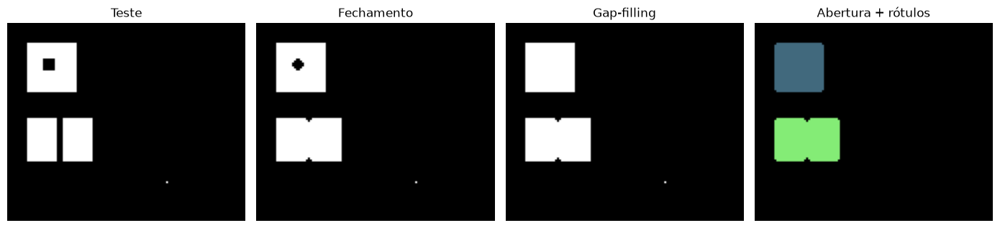

In [32]:
teste=np.zeros((100,120),dtype=bool)
teste[10:35,10:35]=True; teste[18:24,18:24]=False
teste[48:70,10:25]=True; teste[48:70,28:43]=True; teste[80,80]=True
rot_a,comp_a,_=rotular_componentes(teste,1); fechada=fechamento(teste,2); preenchida,buracos=preencher_buracos(fechada); final=abertura(preenchida,1); rot_d,comp_d,_=rotular_componentes(final,1)
assert len(comp_a)==4 and len(comp_d)==2 and existe_verdadeiro(buracos) and final[20,20] and not final[80,80]
assert len(offsets_elemento(2, "disco")) == 13
assert len(offsets_elemento(2, "quadrado")) == 25
assert len(offsets_elemento(2, "cruz")) == 9
print('TESTES OK: gap-filling, conectividade, remoção de ruído e elementos disco/quadrado/cruz.')
fig,ax=plt.subplots(1,4,figsize=(14,3.5))
for eixo,imagem,titulo,cmap in zip(ax,[teste,fechada,preenchida,colorir_rotulos(rot_d)],['Teste','Fechamento','Gap-filling','Abertura + rótulos'],['gray','gray','gray',None]): eixo.imshow(imagem,cmap=cmap); eixo.set_title(titulo); eixo.axis('off')
plt.tight_layout(); plt.show()

## 6. Execução nas duas imagens reais


In [33]:
def encontrar_imagens():
    # Retorna {nome: caminho} para as imagens encontradas em data/ e uma mensagem de aviso (ou None).
    pasta = Path("data")
    if not pasta.is_dir():
        return {}, "Pasta data/ não encontrada ao lado do notebook."
    nomes = list(CONFIG.keys())
    achadas = {n: pasta / arq for n, arq in zip(nomes, NOMES_ARQUIVOS) if (pasta / arq).is_file()}
    faltando = [arq for n, arq in zip(nomes, NOMES_ARQUIVOS) if n not in achadas]
    aviso = ("Arquivo(s) não encontrado(s) em data/: " + ", ".join(faltando)) if faltando else None
    return achadas, aviso
def executar_pipeline(caminho, config):
    cinza = ler_cinza(caminho)
    limiar = otsu_manual(cinza)
    binaria = binarizar(cinza, limiar, config["inverter"])

    # Contagem bruta inicial, sem filtro de área.
    rot_binaria, comp_binaria, bruto_binaria = rotular_componentes(binaria, 1)

    fechada = fechamento(binaria, config["raio_fechamento"], config["forma"])
    rot_fechada, comp_fechada, bruto_fechada = rotular_componentes(fechada, 1)

    # Gap-filling isolado: a contagem é feita imediatamente após preencher,
    # antes de abertura ou filtro de área.
    preenchida, buracos = preencher_buracos(fechada)
    rot_preenchida, comp_preenchida, bruto_preenchida = rotular_componentes(preenchida, 1)

    aberta = abertura(preenchida, config["raio_abertura"], config["forma"])
    rot_aberta, comp_aberta, bruto_aberta = rotular_componentes(aberta, 1)

    # Filtro de área é relatado separadamente da contagem bruta.
    rot_antes_valida, comp_antes_validos, _ = rotular_componentes(binaria, config["area_minima"])
    rot_final, comp_final_validos, bruto_final = rotular_componentes(aberta, config["area_minima"])

    return {
        "arquivo": caminho.name, "cinza": cinza, "limiar": limiar,
        "binaria": binaria, "fechada": fechada, "preenchida": preenchida,
        "buracos": buracos, "aberta": aberta,
        "rot_antes": rot_binaria, "rot_depois": rot_final,
        "rot_preenchida": rot_preenchida, "mascara_final": rot_final > 0,
        "bruto_antes": bruto_binaria, "bruto_fechamento": bruto_fechada,
        "bruto_apos_gap": bruto_preenchida, "bruto_apos_abertura": bruto_aberta,
        "bruto_depois": bruto_final,
        "contagem_antes_bruta": len(comp_binaria),
        "contagem_apos_fechamento_bruta": len(comp_fechada),
        "contagem_apos_gap_bruta": len(comp_preenchida),
        "contagem_apos_abertura_bruta": len(comp_aberta),
        "contagem_antes": len(comp_antes_validos),
        "contagem_depois": len(comp_final_validos),
        "area_minima": config["area_minima"], "forma": config["forma"]
    }


RESULTADOS = []
achadas, aviso = encontrar_imagens()
if aviso:
    print("AVISO:", aviso)
for nome, config in CONFIG.items():
    if nome not in achadas:
        print(f"{nome}: ignorada (arquivo ausente).")
        continue
    r = executar_pipeline(achadas[nome], config)
    r["nome"] = nome
    RESULTADOS.append(r)
    binaria = contar_valores_distintos(r["cinza"]) <= 2
    obs = " (imagem já binária: o Otsu apenas separa os dois níveis)" if binaria else ""
    print(f"{nome}: {achadas[nome].name} | Otsu={r['limiar']}{obs} | "
          f"válidos antes={r['contagem_antes']} -> depois={r['contagem_depois']}")


Imagem 1: gap-region-filling.tif | Otsu=0 (imagem já binária: o Otsu apenas separa os dois níveis) | válidos antes=16 -> depois=16
Imagem 2: 002f20ad-2ace-499c-9335-c9080bc3e6b5.png | Otsu=161 | válidos antes=58 -> depois=57


## 7. Visualização e resultados


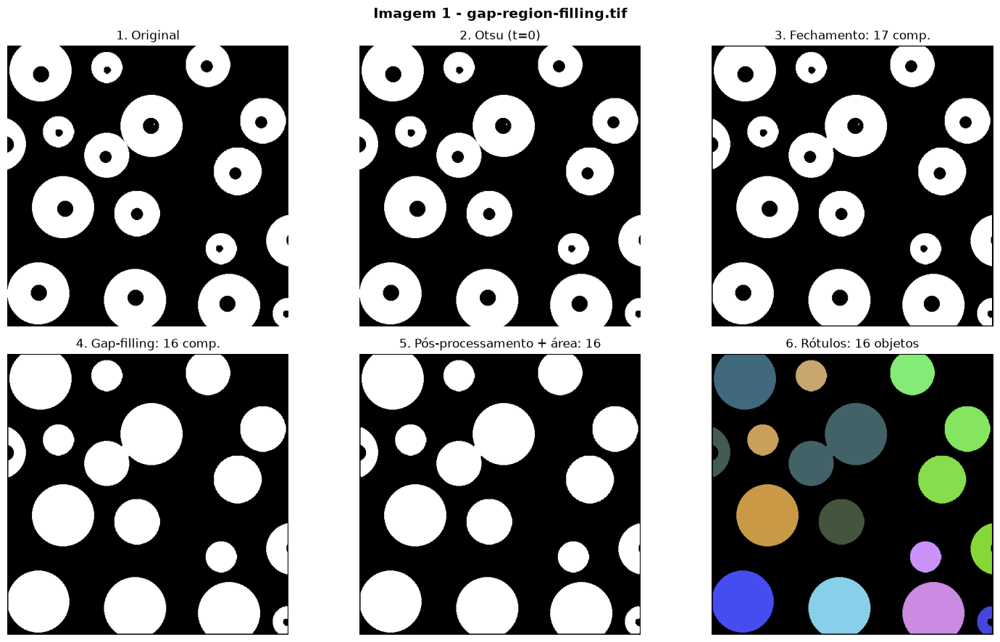

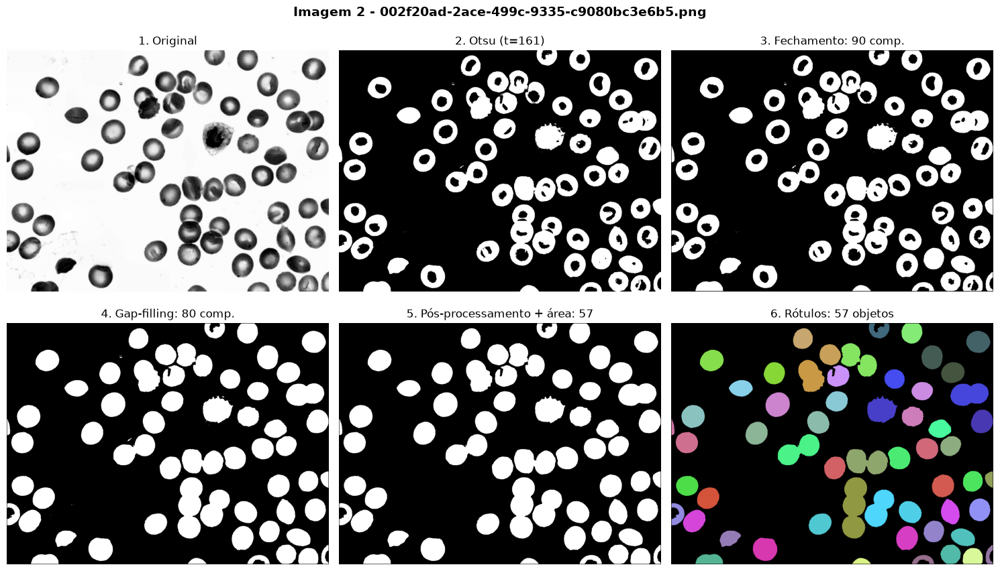

CONTAGEM POR ETAPA (componentes brutos, sem filtro de área)
Imagem 1: binária=17 -> fechamento=17 -> gap-filling=16 -> abertura=16.
Imagem 2: binária=211 -> fechamento=90 -> gap-filling=80 -> abertura=60.
CONTAGEM COM FILTRO DE ÁREA (200 px)
Imagem 1: antes=16 -> final=16.
Imagem 2: antes=58 -> final=57.


In [34]:
def mostrar_resultado(r):
    fig, ax = plt.subplots(2, 3, figsize=(15, 9))
    fig.suptitle(f'{r["nome"]} - {r["arquivo"]}', fontsize=14, fontweight='bold')
    paineis = [
        (r['cinza'], '1. Original', 'gray'),
        (r['binaria'], f'2. Otsu (t={r["limiar"]})', 'gray'),
        (r['fechada'], f'3. Fechamento: {r["contagem_apos_fechamento_bruta"]} comp.', 'gray'),
        (r['preenchida'], f'4. Gap-filling: {r["contagem_apos_gap_bruta"]} comp.', 'gray'),
        (r['mascara_final'], f'5. Pós-processamento + área: {r["contagem_depois"]}', 'gray'),
        (colorir_rotulos(r['rot_depois']), f'6. Rótulos: {r["contagem_depois"]} objetos', None)
    ]
    for eixo, (imagem, titulo, cmap) in zip(ax.flat, paineis):
        eixo.imshow(imagem, cmap=cmap)
        eixo.set_title(titulo)
        eixo.axis('off')
    plt.tight_layout()
    plt.show()

for r in RESULTADOS:
    mostrar_resultado(r)

if RESULTADOS:
    print('CONTAGEM POR ETAPA (componentes brutos, sem filtro de área)')
    for r in RESULTADOS:
        print(
            f'{r["nome"]}: binária={r["contagem_antes_bruta"]} -> '
            f'fechamento={r["contagem_apos_fechamento_bruta"]} -> '
            f'gap-filling={r["contagem_apos_gap_bruta"]} -> '
            f'abertura={r["contagem_apos_abertura_bruta"]}.'
        )
    print('CONTAGEM COM FILTRO DE ÁREA (200 px)')
    for r in RESULTADOS:
        print(f'{r["nome"]}: antes={r["contagem_antes"]} -> final={r["contagem_depois"]}.')
else:
    print('Os painéis das imagens reais aparecerão após incluir os dois arquivos em data/.')


## 8. Gráficos comparativos


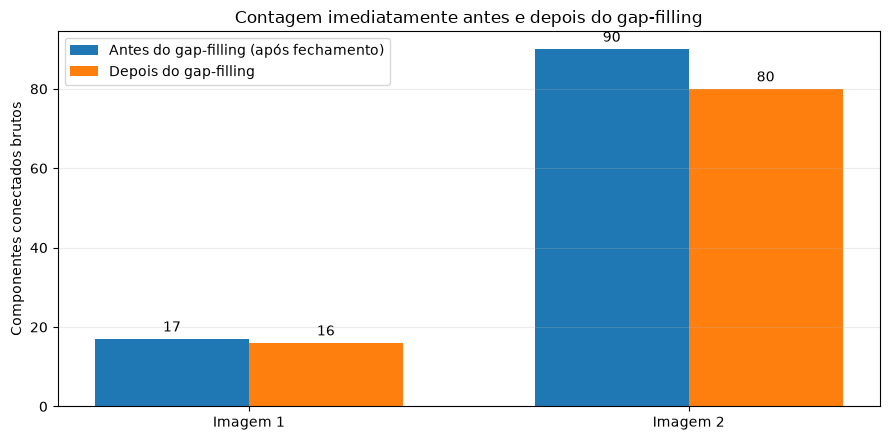

Imagem 1: ocupação (%) = 35.32, 34.97, 37.38, 37.38
Imagem 2: ocupação (%) = 24.00, 24.19, 28.05, 28.03


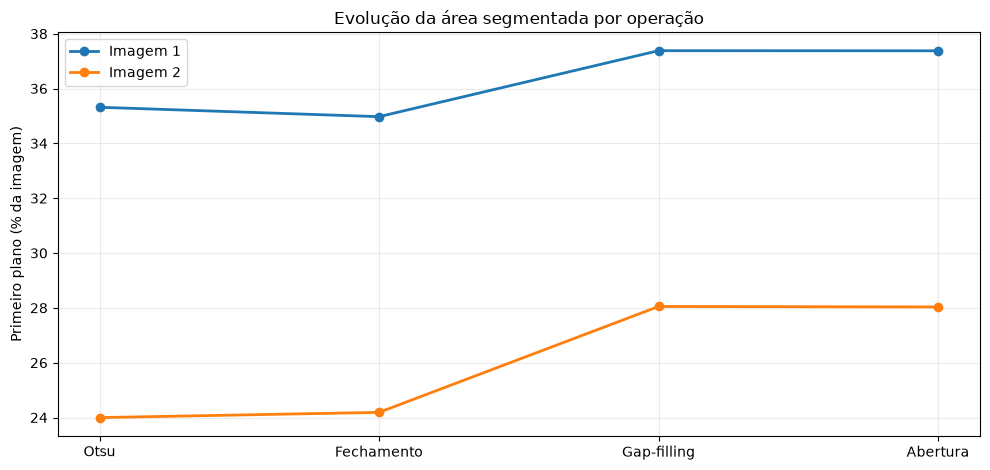

In [35]:
if RESULTADOS:
    x = np.arange(len(RESULTADOS))
    antes = [r['contagem_apos_fechamento_bruta'] for r in RESULTADOS]
    depois_gap = [r['contagem_apos_gap_bruta'] for r in RESULTADOS]
    largura = .35
    fig, ax = plt.subplots(figsize=(9, 4.5))
    a = ax.bar(x-largura/2, antes, largura, label='Antes do gap-filling (após fechamento)')
    b = ax.bar(x+largura/2, depois_gap, largura, label='Depois do gap-filling')
    ax.bar_label(a, padding=3)
    ax.bar_label(b, padding=3)
    ax.set_xticks(x, [r['nome'] for r in RESULTADOS])
    ax.set_ylabel('Componentes conectados brutos')
    ax.set_title('Contagem imediatamente antes e depois do gap-filling')
    ax.legend()
    ax.grid(axis='y', alpha=.25)
    plt.tight_layout()
    plt.show()

    etapas = ['Otsu', 'Fechamento', 'Gap-filling', 'Abertura']
    fig, ax = plt.subplots(figsize=(10, 4.8))
    for r in RESULTADOS:
        ocup = [
            100*proporcao(r['binaria']), 100*proporcao(r['fechada']),
            100*proporcao(r['preenchida']), 100*proporcao(r['aberta'])
        ]
        ax.plot(etapas, ocup, '-o', lw=2, label=r['nome'])
        print(r['nome'] + ': ocupação (%) = ' + ', '.join(f'{v:.2f}' for v in ocup))
    ax.set_ylabel('Primeiro plano (% da imagem)')
    ax.set_title('Evolução da área segmentada por operação')
    ax.legend()
    ax.grid(alpha=.25)
    plt.tight_layout()
    plt.show()
else:
    print('Os gráficos dependem das duas imagens reais.')


In [36]:
# Resumo quantitativo da Parte 2, gerado da execução corrente.
for r in RESULTADOS:
    ef_gap = r["contagem_apos_gap_bruta"] - r["contagem_apos_fechamento_bruta"]
    print(f"{r['nome']} ({r['arquivo']}): Otsu={r['limiar']}")
    print(f"  Componentes brutos (sem filtro de área): binária={r['contagem_antes_bruta']} -> fechamento={r['contagem_apos_fechamento_bruta']} "
          f"-> gap-filling={r['contagem_apos_gap_bruta']} -> abertura={r['contagem_apos_abertura_bruta']}")
    print(f"  Efeito isolado do gap-filling na contagem: {ef_gap:+d} componente(s); pixels preenchidos: {contar_verdadeiros(r['buracos'])}")
    print(f"  Com filtro de área >= {r['area_minima']} px: antes={r['contagem_antes']} -> depois={r['contagem_depois']}")
    print(f"  Ocupação do primeiro plano: {100*proporcao(r['binaria']):.2f}% -> {100*proporcao(r['aberta']):.2f}%")
if not RESULTADOS:
    print("Nenhuma imagem processada: confira a pasta data/.")

Imagem 1 (gap-region-filling.tif): Otsu=0
  Componentes brutos (sem filtro de área): binária=17 -> fechamento=17 -> gap-filling=16 -> abertura=16
  Efeito isolado do gap-filling na contagem: -1 componente(s); pixels preenchidos: 6310
  Com filtro de área >= 200 px: antes=16 -> depois=16
  Ocupação do primeiro plano: 35.32% -> 37.38%
Imagem 2 (002f20ad-2ace-499c-9335-c9080bc3e6b5.png): Otsu=161
  Componentes brutos (sem filtro de área): binária=211 -> fechamento=90 -> gap-filling=80 -> abertura=60
  Efeito isolado do gap-filling na contagem: -10 componente(s); pixels preenchidos: 74159
  Com filtro de área >= 200 px: antes=58 -> depois=57
  Ocupação do primeiro plano: 24.00% -> 28.03%


### 8.1. Estimativa da subcontagem por área (análise complementar)

A rotulagem conta componentes conectados, então células encostadas viram um único objeto. Quando as células têm tamanho parecido (hemácias da Imagem 2), a área de um componente dividida pela área mediana estima quantas células ele contém. A mediana é obtida pelo percentil manual (sem ordenação). Na Imagem 1 os anéis têm tamanhos muito diferentes, então essa hipótese não vale e a estimativa não é aplicada. Esta análise **não altera** a contagem oficial; serve para quantificar o erro de subcontagem.

In [37]:
for r in RESULTADOS:
    if not CONFIG[r["nome"]]["tamanho_homogeneo"]:
        print(f"{r['nome']}: tamanhos heterogêneos, estimativa por área não aplicável.")
        continue
    _, comps, _ = rotular_componentes(r["mascara_final"], r["area_minima"])
    areas = np.array([c["area"] for c in comps], dtype=float)
    mediana = percentil_por_histograma(areas, 50)          # mediana sem ordenação
    estimativa, suspeitos = 0, 0
    for a in areas.tolist():
        k = int(a / mediana + 0.5)                          # arredondamento para o inteiro mais próximo
        estimativa += k if k > 1 else 1
        if a >= 1.5 * mediana: suspeitos += 1
    print(f"{r['nome']}: {len(comps)} componentes | área mediana ≈ {mediana:.0f} px | "
          f"componentes com área >= 1,5x a mediana (prováveis grupos de células): {suspeitos} | "
          f"estimativa de células ≈ {estimativa} (subcontagem ≈ {estimativa - len(comps)})")

Imagem 1: tamanhos heterogêneos, estimativa por área não aplicável.
Imagem 2: 57 componentes | área mediana ≈ 9198 px | componentes com área >= 1,5x a mediana (prováveis grupos de células): 8 | estimativa de células ≈ 66 (subcontagem ≈ 9)


## 9. Discussão e conclusão (Parte 2)

Os números (limiares, contagens por etapa, pixels preenchidos e ocupação) são impressos pela célula de resumo acima. A interpretação segue estes pontos:

- **Otsu em imagem já binária:** quando a imagem só tem dois níveis, o limiar de Otsu (por exemplo, 0) apenas separa esses níveis; não é uma separação adaptativa complexa.
- **Efeito do gap-filling:** preencher buracos só acrescenta pixels de fundo cercados por objeto; nunca cria componentes. A contagem só diminui quando há partículas ou fragmentos dentro de um buraco, que são incorporados ao objeto preenchido. Por isso o efeito isolado é medido comparando a contagem **imediatamente antes** (após o fechamento) e **depois** do preenchimento, sem abertura nem filtro de área.
- **Fechamento, abertura e filtro de área:** o fechamento conecta fragmentos e pequenas lacunas; a abertura remove partículas pequenas; o filtro de área descarta componentes menores que o mínimo. Por isso a contagem bruta (sem filtro) e a válida (com filtro) devem ser lidas separadamente, e a variação total não deve ser atribuída só ao gap-filling.
- **Limitações:** células encostadas permanecem unidas em um único componente (subcontagem); furos que tocam a borda da imagem estão ligados ao fundo externo e não são preenchidos; objetos pequenos reais podem ser removidos pelo filtro de área. As contagens são de componentes conectados da máscara, não uma validação do número real de células, que exigiria anotação manual.
- **Erro observado nas imagens reais:** na Imagem 1 há 17 anéis visíveis, mas dois estão encostados e formam um único componente, por isso a contagem final é 16 (subcontagem de 1). Na Imagem 2, a estimativa por área (seção 8.1) indica cerca de 9 células a mais do que os 57 componentes, concentradas em pares e trios de hemácias encostadas. Separar esses grupos exigiria uma etapa adicional (por exemplo, transformada de distância seguida de Watershed), que está fora do escopo puramente morfológico desta parte.